# Data Preprocessing: Prediksi Churn Pelanggan ISP

**Mata kuliah:** Data Mining

**Nama:** Siti Fatimah Azzahra  |  **NIM:** 3022410054

**Partner pemberi kasus:** Kesia | **NIM:**  3022410046

**Dataset:** `churn_isp_kotor.csv` (565 baris, 17 variabel)

**Strategi yang dipilih**

| Masalah | Strategi | Alasan singkat |
|---|---|---|
| Missing numerik (Usia, Skor_Kepuasan) | Median | Tahan terhadap nilai ekstrem, mean dan median dibandingkan lebih dulu |
| Missing kategorik (Jenis_Kelamin, Kota, Metode_Bayar) | Modus | Satu-satunya statistik deskriptif yang berlaku untuk data kategorik |
| Missing Tagihan_Bulanan_IDR | Dipulihkan dari Tagihan_Bulanan_USD x kurs | Kurs di data tetap, jadi hasilnya hampir tepat |
| Missing Lama_Langganan_Bulan (setelah nilai mustahil dihapus) | Dipulihkan dari Total_Tagihan / Tagihan_Bulanan | Hubungan antar kolom diketahui |
| Nilai mustahil | Diubah jadi NaN lalu ditangani sebagai missing | Sesuai materi: validasi dulu, lalu perlakukan sebagai missing |
| Outlier statistik | Capping dengan batas IQR (pembanding: Z-score) | Data tidak dibuang, nilai ekstrem dibatasi |
| Atribut redundan | Buang Tagihan_Bulanan_USD dan Total_Tagihan_IDR | Keduanya dapat dihitung persis dari kolom lain |
| Ketidakseimbangan Churn | SMOTE-NC (SMOTE untuk data campuran numerik dan kategorik), hanya pada data latih | Mencegah kebocoran data ke data uji |

## Persiapan

**Input:** library Python dan file `churn_isp_kotor.csv`.
**Proses:** impor library, baca file CSV, simpan salinan data mentah untuk perbandingan.
**Output:** DataFrame `data` yang siap dieksplorasi.

In [131]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (MinMaxScaler, StandardScaler, RobustScaler,
                                   LabelEncoder, OrdinalEncoder)
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

In [132]:
# Jalankan di folder yang sama dengan file CSV (lokal/GitHub). Di Google Colab, unggah file ke /content.
path = "churn_isp_kotor.csv"
if not os.path.exists(path):
    path = "/content/churn_isp_kotor.csv"

data = pd.read_csv(path)
data_mentah = data.copy()
data.head(10)

,ID_Pelanggan,Usia,Jenis_Kelamin,Kota,Paket,Lama_Langganan_Bulan,Tagihan_Bulanan_IDR,Total_Tagihan_IDR,Jumlah_Keluhan,Skor_Kepuasan,Metode_Bayar,Tanggal_Daftar,Tagihan_Bulanan_USD,Negara,Penggunaan_Data_GB,Periode_Penggunaan,Churn
0,cust1526@@,38.0,Perempuan,Yogyakarta,BASIC,17.0,378900.0,6441300.0,0,NaN,Transfer Bank,09/07/2024,23.68,Indonesia,155.7,Bulanan,0
1,CUST1033,45.0,Perempuan,Medan,Standard,22.0,403900.0,8885800.0,1,6.0,Transfer Bank,10/02/2024,25.24,Indonesia,403.7,Bulanan,1
2,CUST1465,48.0,P,Jakarta,Standard,56.0,384400.0,21526400.0,1,9.0,E-Wallet,26 April 2021,24.02,Indonesia,430.9,Bulanan,0
3,cust1585@@,36.0,Laki-laki,Surabaya,Standard,8.0,381300.0,3050400.0,0,NaN,Virtual Account,05 April 2025,23.83,Indonesia,334.7,Bulanan,1
4,CUST1436,36.0,Laki-laki,Semarang,Standard,11.0,409700.0,4506700.0,1,NaN,NaN,05/01/2025,25.61,Indonesia,83.3,Mingguan,0
5,CUST1548,21.0,Perempuan,Surabaya,Basic,31.0,259400.0,8041400.0,1,8.0,NaN,16 May 2023,16.21,Indonesia,215.4,Bulanan,0
6,CUST1234,39.0,Laki-laki,Surabaya,Basic,35.0,240500.0,8417500.0,1,6.0,Virtual Account,16 January 2023,15.03,Indonesia,271.0,Bulanan,0
7,CUST1241,21.0,NaN,Yogyakarta,Standard,13.0,392.8,5106400.0,40,6.0,Virtual Account,2024-11-06,24.55,Indonesia,582.1,Bulanan,0
8,CUST1555,43.0,Laki-laki,Makassar,Basic,54.0,246100.0,13289400.0,1,NaN,E-Wallet,2021-06-25,15.38,Indonesia,179.6,Bulanan,0
9,CUST1071,27.0,L,Bandung,Standard,13.0,420000.0,5460000.0,0,8.0,NaN,11-06-24,26.25,Indonesia,584.7,Bulanan,0


## Tahap 1: Deteksi Masalah Data (Eksplorasi Awal)

**Input:** DataFrame `data` hasil pembacaan CSV.
**Proses:** cek ukuran data, tipe data, statistik deskriptif, jumlah missing value, jumlah duplikat, dan isi tiap kolom kategorik. Cek juga kolom yang seharusnya numerik tetapi terbaca sebagai teks.
**Output:** daftar temuan awal yang menjadi dasar tahap cleansing.

In [133]:
print("Ukuran data (baris, kolom):", data.shape)
data.info()

Ukuran data (baris, kolom): (565, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 565 entries, 0 to 564
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID_Pelanggan          565 non-null    object 
 1   Usia                  533 non-null    object 
 2   Jenis_Kelamin         542 non-null    object 
 3   Kota                  549 non-null    object 
 4   Paket                 565 non-null    object 
 5   Lama_Langganan_Bulan  565 non-null    float64
 6   Tagihan_Bulanan_IDR   541 non-null    object 
 7   Total_Tagihan_IDR     565 non-null    float64
 8   Jumlah_Keluhan        565 non-null    int64  
 9   Skor_Kepuasan         531 non-null    object 
 10  Metode_Bayar          537 non-null    object 
 11  Tanggal_Daftar        565 non-null    object 
 12  Tagihan_Bulanan_USD   565 non-null    float64
 13  Negara                565 non-null    object 
 14  Penggunaan_Data_GB    565 non-null  

In [134]:
# Statistik deskriptif kolom numerik. Usia, Tagihan_Bulanan_IDR, dan Skor_Kepuasan tidak muncul
# karena terbaca sebagai teks (ada karakter non-angka di dalamnya).
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Lama_Langganan_Bulan,565.0,2.283007e+01,1.556018e+01,-12.00,11.00,20.00,31.00,7.200000e+01
Total_Tagihan_IDR,565.0,1.267954e+07,4.318239e+07,244100.00,4044600.00,7395000.00,13244000.00,7.632000e+08
Jumlah_Keluhan,565.0,1.532743e+00,3.438581e+00,0.00,0.00,1.00,2.00,4.000000e+01
Tagihan_Bulanan_USD,565.0,2.490648e+01,9.476921e+00,14.22,15.74,24.57,26.19,4.469000e+01
Penggunaan_Data_GB,565.0,3.503292e+02,2.835564e+02,35.90,147.00,249.70,487.30,1.198300e+03
Churn,565.0,1.079646e-01,3.106107e-01,0.00,0.00,0.00,0.00,1.000000e+00


In [135]:
print("Jumlah missing value per kolom:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print("\nJumlah baris duplikat (seluruh kolom sama):", data.duplicated().sum())
print("Jumlah ID_Pelanggan duplikat:", data["ID_Pelanggan"].duplicated().sum())

Jumlah missing value per kolom:
Usia                   32
Jenis_Kelamin          23
Kota                   16
Tagihan_Bulanan_IDR    24
Skor_Kepuasan          34
Metode_Bayar           28
dtype: int64

Jumlah baris duplikat (seluruh kolom sama): 19
Jumlah ID_Pelanggan duplikat: 19


In [136]:
# Deteksi salah ketik, huruf besar-kecil, dan spasi berlebih pada kolom kategorik
for kolom in ["Jenis_Kelamin", "Kota", "Paket", "Metode_Bayar", "Negara", "Periode_Penggunaan", "Churn"]:
    print("-----", kolom)
    print(data[kolom].apply(repr).value_counts(dropna=False).to_string())

----- Jenis_Kelamin
Jenis_Kelamin
'Laki-laki'    252
'Perempuan'    248
nan             23
'P'             21
'L'             21
----- Kota
Kota
'Jakarta'        119
'Surabaya'        90
'Bandung'         83
'Medan'           57
'Yogyakarta'      49
'Semarang'        48
'Makassar'        46
nan               16
'Jkt'             12
'JAKARTA'          5
'SURABAYA'         5
'SEMARANG'         5
'jakarta '         5
'yogyakarta '      4
'semarang '        4
'MAKASSAR'         3
'surabaya '        3
'medan '           3
'YOGYAKARTA'       2
'makassar '        2
'bandung '         2
'MEDAN'            1
'BANDUNG'          1
----- Paket
Paket
'Basic'       196
'Standard'    195
'Premium'     124
'premium'      26
' BASIC'       24
----- Metode_Bayar
Metode_Bayar
'E-Wallet'           157
'Transfer Bank'      155
'Virtual Account'    106
'Kartu Kredit'        82
nan                   28
'Ewallet'             19
'transfer bank'       18
----- Negara
Negara
'Indonesia'    565
----- Periode_Peng

In [137]:
# Deteksi nilai non-angka pada kolom yang seharusnya numerik
for kolom in ["Usia", "Tagihan_Bulanan_IDR", "Skor_Kepuasan"]:
    s = data[kolom].dropna().astype(str)
    salah = s[pd.to_numeric(s, errors="coerce").isna()]
    print(f"{kolom}: {len(salah)} nilai non-angka, contoh: {list(salah.unique()[:5])}")

# Deteksi format tanggal yang bercampur
pola = {
    "ISO  (YYYY-MM-DD)":    (r"^\d{4}-\d{2}-\d{2}$",          "%Y-%m-%d"),
    "Garis miring (DD/MM/YYYY)": (r"^\d{1,2}/\d{1,2}/\d{4}$",  "%d/%m/%Y"),
    "Teks (DD Bulan YYYY)": (r"^\d{1,2} [A-Za-z]+ \d{4}$",      "%d %B %Y"),
    "Garis (MM-DD-YY)":     (r"^\d{1,2}-\d{1,2}-\d{2}$",       "%m-%d-%y"),
}
tgl = data["Tanggal_Daftar"].astype(str).str.strip()
for nama, (regex, fmt) in pola.items():
    print(f"{nama:28s}: {tgl.str.match(regex).sum()} baris")

Usia: 13 nilai non-angka, contoh: ['24 th', '32 th', '51 th', '36 th', '42 th']
Tagihan_Bulanan_IDR: 21 nilai non-angka, contoh: ['Rp239500', 'Rp399600', 'Rp369100', 'Rp258300', 'Rp252100']
Skor_Kepuasan: 8 nilai non-angka, contoh: ['tidak tahu']
ISO  (YYYY-MM-DD)           : 238 baris
Garis miring (DD/MM/YYYY)   : 162 baris
Teks (DD Bulan YYYY)        : 105 baris
Garis (MM-DD-YY)            : 60 baris


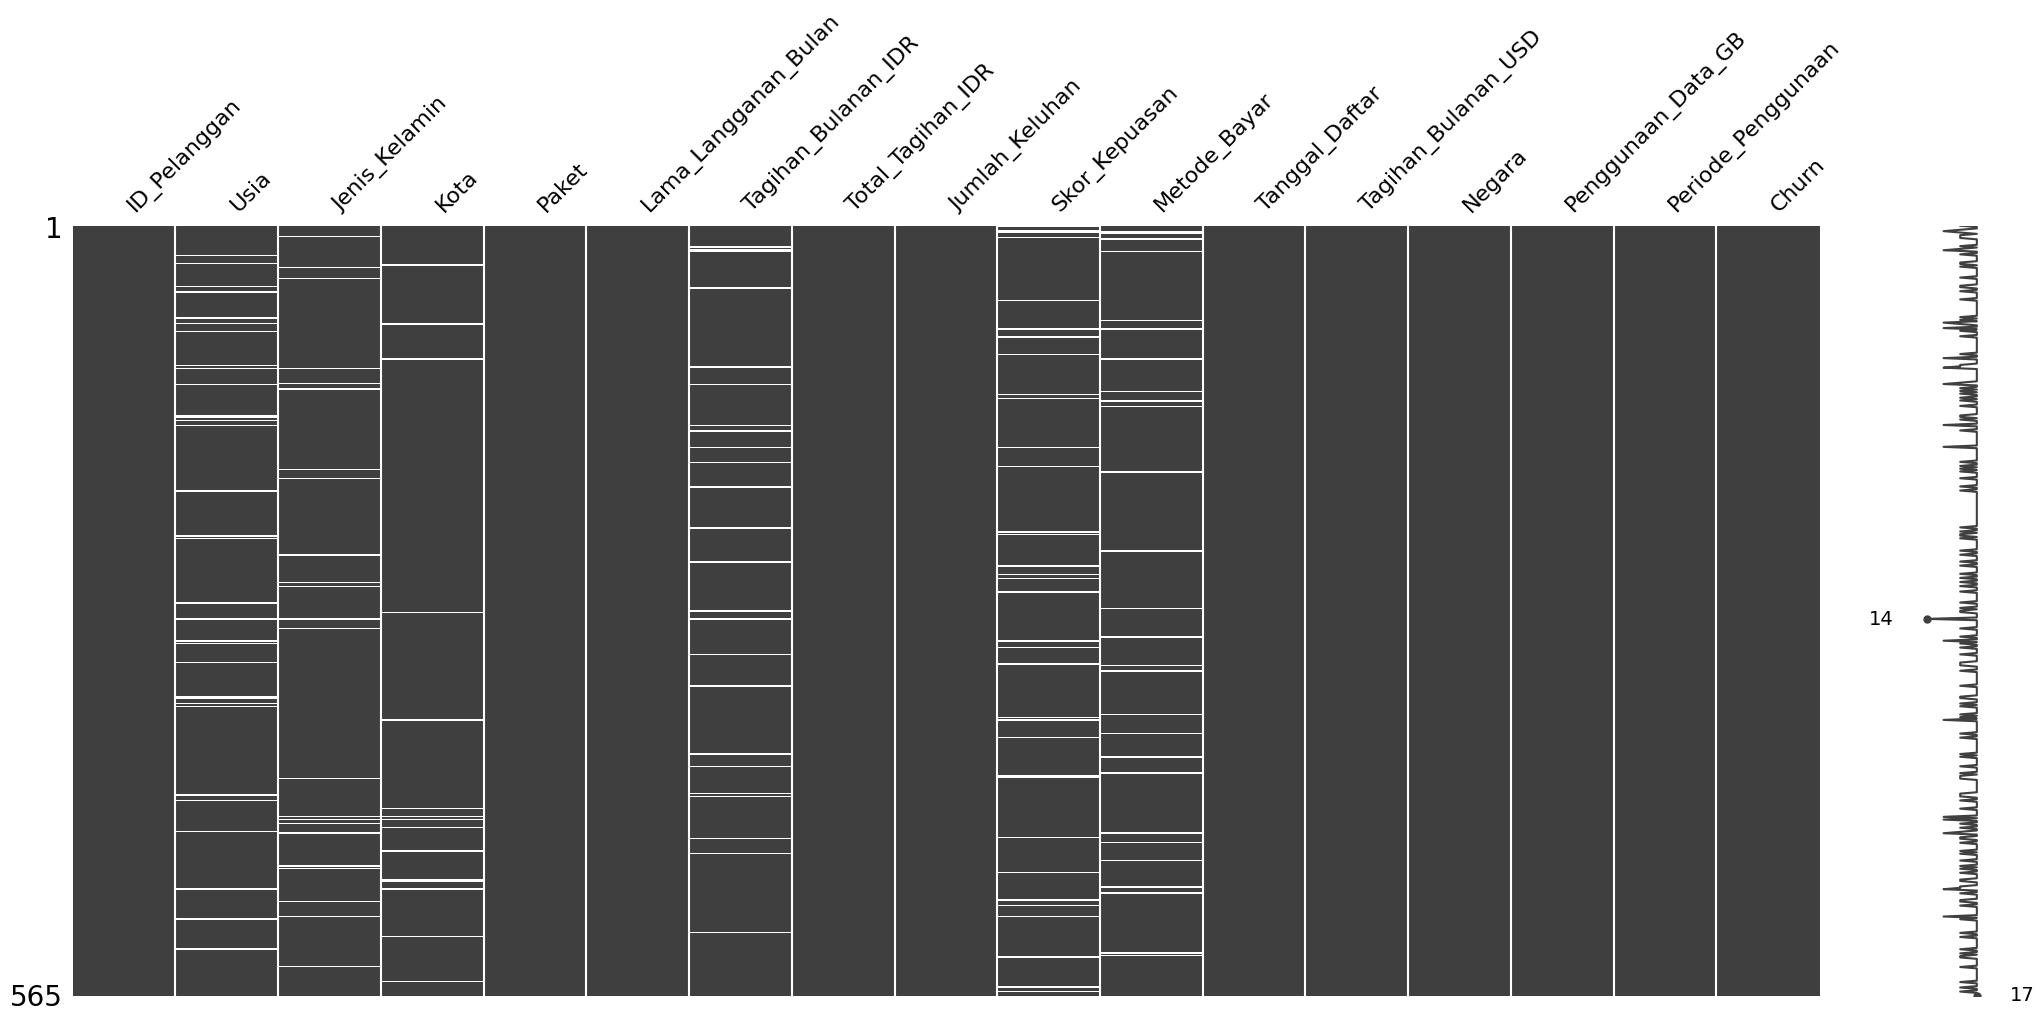

In [138]:
# Visualisasi pola missing value (baris yang kosong tampak sebagai garis terang)
try:
    import missingno as msno
    msno.matrix(data)
except ImportError:
    plt.figure(figsize=(10, 4))
    plt.imshow(data.isnull().values.T, aspect="auto", interpolation="nearest", cmap="gray_r")
    plt.yticks(range(data.shape[1]), data.columns, fontsize=7)
    plt.xlabel("Indeks baris")
    plt.title("Pola missing value (hitam = kosong)")
plt.show()

### 1.x Bukti visual outlier dan nilai ganjil sebelum pembersihan

**Input:** kolom numerik pada data mentah (Usia, Lama_Langganan_Bulan, Total_Tagihan_IDR, Skor_Kepuasan). Usia dan Skor diubah sementara ke angka agar bisa digambar.
**Proses:** histogram dan boxplot dengan data apa adanya.
**Output:** gambar yang memperlihatkan nilai di luar sebaran utama sebelum cleansing.

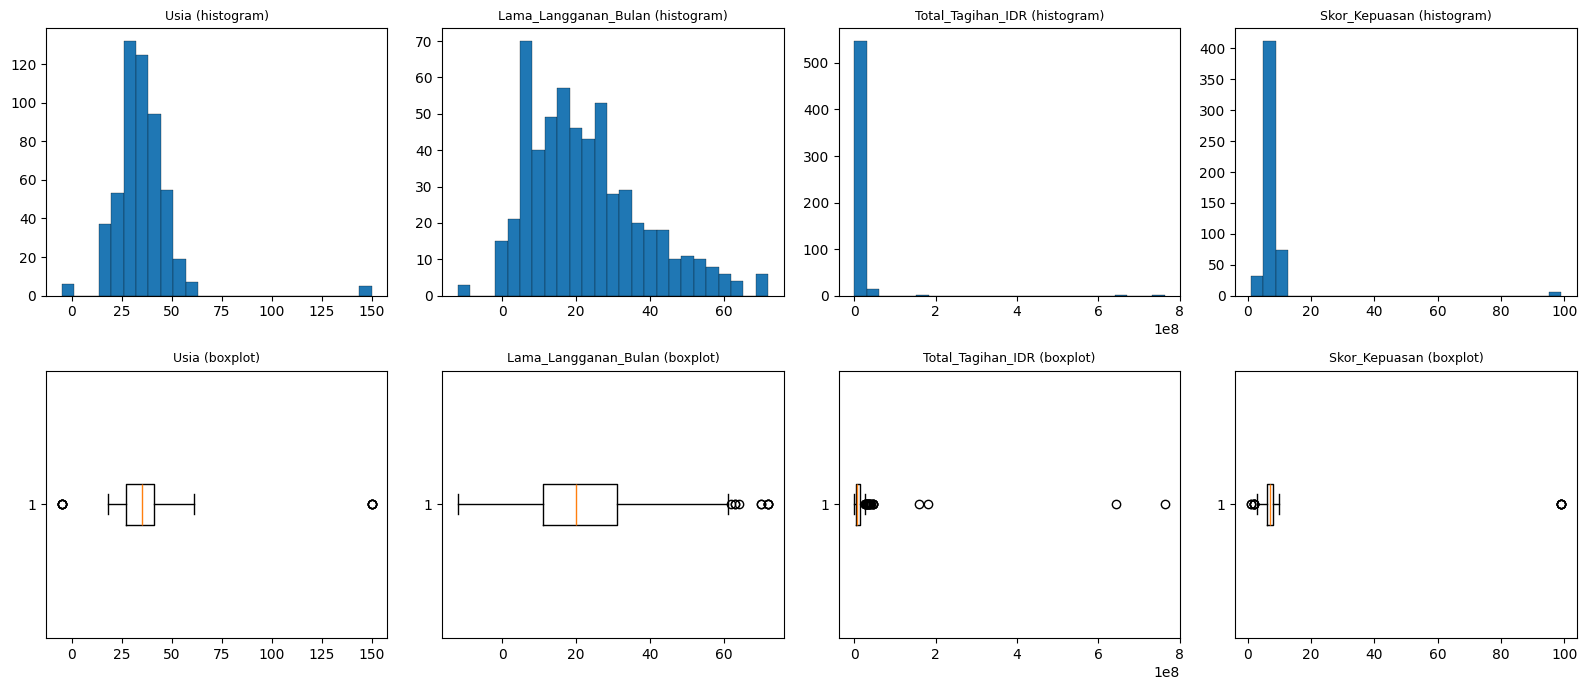

       Usia  Lama_Langganan_Bulan  Total_Tagihan_IDR  Skor_Kepuasan
min    -5.0                 -12.0           244100.0            1.0
max   150.0                  72.0        763200000.0           99.0
mean   35.1                  22.8         12679537.0            8.0


In [139]:
mentah_num = pd.DataFrame({
    "Usia": pd.to_numeric(data["Usia"].astype(str).str.replace("th", "", regex=False).str.strip(), errors="coerce"),
    "Lama_Langganan_Bulan": data["Lama_Langganan_Bulan"],
    "Total_Tagihan_IDR": data["Total_Tagihan_IDR"],
    "Skor_Kepuasan": pd.to_numeric(data["Skor_Kepuasan"], errors="coerce"),
})
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, c in enumerate(mentah_num.columns):
    axes[0, j].hist(mentah_num[c].dropna(), bins=25, edgecolor="black", linewidth=0.2)
    axes[0, j].set_title(c + " (histogram)", fontsize=9)
    axes[1, j].boxplot(mentah_num[c].dropna(), vert=False)
    axes[1, j].set_title(c + " (boxplot)", fontsize=9)
plt.tight_layout(); plt.show()
print(mentah_num.agg(["min", "max", "mean"]).round(1))

**Temuan eksplorasi (ringkasan):**
- 565 baris dan 17 variabel. Ada 19 baris duplikat penuh.
- Missing value numerik: Usia, Tagihan_Bulanan_IDR, Skor_Kepuasan. Missing kategorik: Jenis_Kelamin, Kota, Metode_Bayar.
- Salah ketik dan huruf besar-kecil: "Ewallet", "Jkt", "L"/"P", "premium", "SURABAYA". Spasi berlebih di Kota, Paket, ID_Pelanggan.
- Format tidak konsisten: "24 th" pada Usia, "Rp239500" pada tagihan, "@@" pada ID, empat format tanggal.
- Ada nilai mustahil (Usia -5 dan 150, Lama_Langganan -12, Skor 99) dan nilai ekstrem (Jumlah_Keluhan 40).
- Dugaan beda satuan dan beda level agregasi, yang dibuktikan di tahap 2.5 dan 2.6.

## Tahap 2: Pembersihan Data

### 2.1 Spasi berlebih (redundant whitespace)

**Input:** kolom bertipe teks pada `data`.
**Proses:** hapus spasi di depan, belakang, dan spasi ganda di tengah dengan `strip()` dan `replace`.
**Output:** nilai teks tanpa spasi berlebih, sehingga "jakarta " dan "Jakarta" bisa dikenali sebagai nilai yang sama.

In [140]:
kolom_teks = [c for c in data.columns
              if data[c].dtype == object or pd.api.types.is_string_dtype(data[c])]
print("Kolom teks:", kolom_teks)

sebelum = {c: int((data[c].dropna() != data[c].dropna().str.strip()).sum()) for c in kolom_teks}
print("Jumlah nilai dengan spasi berlebih (sebelum):", {k: v for k, v in sebelum.items() if v > 0})

for c in kolom_teks:
    data[c] = data[c].str.strip().str.replace(r"\s+", " ", regex=True)

sesudah = {c: int((data[c].dropna() != data[c].dropna().str.strip()).sum()) for c in kolom_teks}
print("Jumlah nilai dengan spasi berlebih (sesudah):", {k: v for k, v in sesudah.items() if v > 0} or "tidak ada")

Kolom teks: ['ID_Pelanggan', 'Usia', 'Jenis_Kelamin', 'Kota', 'Paket', 'Tagihan_Bulanan_IDR', 'Skor_Kepuasan', 'Metode_Bayar', 'Tanggal_Daftar', 'Negara', 'Periode_Penggunaan']
Jumlah nilai dengan spasi berlebih (sebelum): {'ID_Pelanggan': 23, 'Kota': 23, 'Paket': 24}
Jumlah nilai dengan spasi berlebih (sesudah): tidak ada


### 2.2 Kesalahan input dan inkonsistensi kategori

**Input:** kolom ID_Pelanggan, Kota, Paket, Jenis_Kelamin, Metode_Bayar.
**Proses:** samakan huruf besar-kecil (`title()`, `upper()`), buang karakter "@@", lalu ganti singkatan dan variasi penulisan dengan `replace` ke satu bentuk baku.
**Output:** setiap kategori hanya punya satu penulisan.

In [141]:
data["ID_Pelanggan"] = data["ID_Pelanggan"].str.replace("@", "", regex=False).str.upper()
data["Kota"]         = data["Kota"].str.title().replace({"Jkt": "Jakarta"})
data["Paket"]        = data["Paket"].str.title()
data["Jenis_Kelamin"] = data["Jenis_Kelamin"].replace({"L": "Laki-laki", "P": "Perempuan"})
data["Metode_Bayar"] = (data["Metode_Bayar"].str.lower()
                        .replace({"transfer bank": "Transfer Bank", "e-wallet": "E-Wallet",
                                  "ewallet": "E-Wallet", "kartu kredit": "Kartu Kredit",
                                  "virtual account": "Virtual Account"}))

for kolom in ["Jenis_Kelamin", "Kota", "Paket", "Metode_Bayar"]:
    print("-----", kolom)
    print(data.groupby(kolom).size().to_string())
print("\nContoh ID_Pelanggan:", list(data["ID_Pelanggan"].head(5)))

----- Jenis_Kelamin
Jenis_Kelamin
Laki-laki    273
Perempuan    269
----- Kota
Kota
Bandung        86
Jakarta       141
Makassar       51
Medan          61
Semarang       57
Surabaya       98
Yogyakarta     55
----- Paket
Paket
Basic       220
Premium     150
Standard    195
----- Metode_Bayar
Metode_Bayar
E-Wallet           176
Kartu Kredit        82
Transfer Bank      173
Virtual Account    106

Contoh ID_Pelanggan: ['CUST1526', 'CUST1033', 'CUST1465', 'CUST1585', 'CUST1436']


### 2.3 Format data tidak konsisten (tipe data)

**Input:** Usia ("24 th"), Tagihan_Bulanan_IDR ("Rp239500"), Skor_Kepuasan ("tidak tahu"), dan Tanggal_Daftar dengan empat format.
**Proses:** hapus awalan/akhiran non-angka lalu ubah ke numerik. Untuk tanggal, cek dulu urutan hari-bulan di tiap format, kemudian ubah masing-masing format ke `datetime`.
**Output:** Usia, Tagihan, Skor bertipe angka dan Tanggal_Daftar bertipe `datetime`.

In [142]:
data["Usia"] = pd.to_numeric(data["Usia"].str.replace(r"\s*th$", "", regex=True), errors="coerce")
data["Tagihan_Bulanan_IDR"] = pd.to_numeric(data["Tagihan_Bulanan_IDR"].str.replace("Rp", "", regex=False), errors="coerce")
data["Skor_Kepuasan"] = pd.to_numeric(data["Skor_Kepuasan"], errors="coerce")   # "tidak tahu" menjadi NaN

print(data[["Usia", "Tagihan_Bulanan_IDR", "Skor_Kepuasan"]].dtypes)

Usia                   float64
Tagihan_Bulanan_IDR    float64
Skor_Kepuasan          float64
dtype: object


In [143]:
# Bukti urutan tanggal: bagian mana yang pernah bernilai > 12 pasti hari, bukan bulan
tgl = data["Tanggal_Daftar"].astype(str)
slash = tgl[tgl.str.match(pola["Garis miring (DD/MM/YYYY)"][0])].str.split("/", expand=True).astype(int)
garis = tgl[tgl.str.match(pola["Garis (MM-DD-YY)"][0])].str.split("-", expand=True).astype(int)
print("Format garis miring: bagian-1 > 12 =", (slash[0] > 12).sum(), "| bagian-2 > 12 =", (slash[1] > 12).sum(), "-> DD/MM/YYYY")
print("Format garis       : bagian-1 > 12 =", (garis[0] > 12).sum(), "| bagian-2 > 12 =", (garis[1] > 12).sum(), "-> MM-DD-YY")

Format garis miring: bagian-1 > 12 = 53 | bagian-2 > 12 = 0 -> DD/MM/YYYY
Format garis       : bagian-1 > 12 = 0 | bagian-2 > 12 = 21 -> MM-DD-YY


In [144]:
bagian = []
for nama, (regex, fmt) in pola.items():
    mask = tgl.str.match(regex)
    bagian.append(pd.to_datetime(tgl[mask], format=fmt))
data["Tanggal_Daftar"] = pd.concat(bagian).sort_index()

print("Tanggal gagal diubah:", data["Tanggal_Daftar"].isnull().sum())
print("Rentang tanggal     :", data["Tanggal_Daftar"].min().date(), "sampai", data["Tanggal_Daftar"].max().date())

Tanggal gagal diubah: 0
Rentang tanggal     : 2020-01-02 sampai 2025-11-01


### 2.4 Data duplikat

**Input:** `data` setelah teks dan format diseragamkan.
**Proses:** hitung baris duplikat penuh dan duplikat ID_Pelanggan, lalu hapus dengan `drop_duplicates()`.
**Output:** satu baris per pelanggan (565 baris menjadi 546 baris).

In [145]:
print("Duplikat baris penuh :", data.duplicated().sum())
print("Duplikat ID_Pelanggan:", data["ID_Pelanggan"].duplicated().sum())
data[data.duplicated(keep=False)].sort_values("ID_Pelanggan").iloc[:6, :8]

Duplikat baris penuh : 19
Duplikat ID_Pelanggan: 19


,ID_Pelanggan,Usia,Jenis_Kelamin,Kota,Paket,Lama_Langganan_Bulan,Tagihan_Bulanan_IDR,Total_Tagihan_IDR
68,CUST1044,36.0,Perempuan,Jakarta,Premium,6.0,657200.0,3943200.0
130,CUST1044,36.0,Perempuan,Jakarta,Premium,6.0,657200.0,3943200.0
402,CUST1103,45.0,Laki-laki,Bandung,Premium,24.0,665000.0,15960000.0
33,CUST1103,45.0,Laki-laki,Bandung,Premium,24.0,665000.0,15960000.0
529,CUST1112,25.0,Laki-laki,Medan,Standard,27.0,396200.0,10697400.0
257,CUST1112,25.0,Laki-laki,Medan,Standard,27.0,396200.0,10697400.0


In [146]:
data = data.drop_duplicates().reset_index(drop=True)
print("Ukuran data setelah duplikat dihapus:", data.shape)
print("Sisa duplikat ID:", data["ID_Pelanggan"].duplicated().sum())

Ukuran data setelah duplikat dihapus: (546, 17)
Sisa duplikat ID: 0


### 2.5 Beda satuan pengukuran

**Input:** Tagihan_Bulanan_IDR dan Lama_Langganan_Bulan.
**Proses:**
1. Deteksi: kurs IDR/USD seharusnya konstan. Baris dengan kurs jauh di bawah normal berarti tagihan IDR tercatat dalam ribu rupiah.
2. Deteksi: Total_Tagihan / Tagihan_Bulanan seharusnya sama dengan Lama_Langganan. Kalau Lama x 12 yang cocok, berarti lama langganan tercatat dalam tahun.
3. Perbaikan: kalikan 1000 (ribu menjadi rupiah) dan kalikan 12 (tahun menjadi bulan).

**Output:** semua baris memakai satuan yang sama, yaitu rupiah dan bulan.

In [147]:
data["kurs"] = data["Tagihan_Bulanan_IDR"] / data["Tagihan_Bulanan_USD"]
print("Ringkasan kurs sebelum perbaikan:")
print(data["kurs"].describe().round(1).to_string())
print("\nBaris dengan tagihan < 1000 (diduga ribu rupiah):", (data["Tagihan_Bulanan_IDR"] < 1000).sum())
data.loc[data["Tagihan_Bulanan_IDR"] < 1000, ["ID_Pelanggan", "Tagihan_Bulanan_IDR", "Tagihan_Bulanan_USD", "kurs"]].head()

Ringkasan kurs sebelum perbaikan:
count      522.0
mean     15142.5
std       3604.7
min         16.0
25%      15997.6
50%      15999.5
75%      16001.3
max      16005.5

Baris dengan tagihan < 1000 (diduga ribu rupiah): 28


,ID_Pelanggan,Tagihan_Bulanan_IDR,Tagihan_Bulanan_USD,kurs
7,CUST1241,392.8,24.55,16.000000
51,CUST1374,243.2,15.20,16.000000
59,CUST1209,241.2,15.08,15.994695
66,CUST1158,408.1,25.51,15.997648
80,CUST1046,241.5,15.09,16.003976


In [148]:
mask_ribu = data["Tagihan_Bulanan_IDR"] < 1000
data.loc[mask_ribu, "Tagihan_Bulanan_IDR"] = (data.loc[mask_ribu, "Tagihan_Bulanan_IDR"] * 1000).round(0)

data["kurs"] = data["Tagihan_Bulanan_IDR"] / data["Tagihan_Bulanan_USD"]
KURS = round(data["kurs"].median(), -2)
print("Kurs setelah perbaikan: min =", round(data["kurs"].min()), "| maks =", round(data["kurs"].max()), "| kurs yang dipakai =", KURS)
data = data.drop(columns="kurs")

Kurs setelah perbaikan: min = 15995 | maks = 16006 | kurs yang dipakai = 16000.0


In [149]:
# Lama_Langganan: bandingkan dengan perkiraan dari Total_Tagihan / Tagihan_Bulanan
lama = data["Lama_Langganan_Bulan"]
perkiraan = (data["Total_Tagihan_IDR"] / data["Tagihan_Bulanan_IDR"]).round()

mask_tahun = (lama > 0) & (
    (lama % 1 != 0) |
    (((lama * 12 - perkiraan).abs() <= 1) & ((lama - perkiraan).abs() > 1))
)
print("Baris dengan Lama_Langganan dalam tahun:", mask_tahun.sum())
print(pd.DataFrame({"Lama_Langganan": lama[mask_tahun],
                    "Perkiraan_dari_Total": perkiraan[mask_tahun]}).head())

Baris dengan Lama_Langganan dalam tahun: 22
     Lama_Langganan  Perkiraan_dari_Total
26             0.83                  10.0
47             1.92                  23.0
82             0.92                  11.0
110            0.33                   4.0
131            4.00                  48.0


In [150]:
data.loc[mask_tahun, "Lama_Langganan_Bulan"] = (data.loc[mask_tahun, "Lama_Langganan_Bulan"] * 12).round()
print("Sisa nilai Lama_Langganan non-bulat:", (data["Lama_Langganan_Bulan"].dropna() % 1 != 0).sum())
data["Lama_Langganan_Bulan"].describe().round(1).to_frame().T

Sisa nilai Lama_Langganan non-bulat: 0


,count,mean,std,min,25%,50%,75%,max
Lama_Langganan_Bulan,546.0,23.6,15.3,-12.0,12.0,21.0,32.0,72.0


### 2.6 Beda level agregasi

**Input:** Penggunaan_Data_GB dan Periode_Penggunaan (Mingguan / Bulanan).
**Proses:** bandingkan rata-rata pemakaian per periode. Pemakaian mingguan jauh lebih kecil dari bulanan, jadi nilainya belum setara. Faktor konversi dibuktikan dari rasio pemakaian per rupiah tagihan (bulanan : mingguan, hasilnya mendekati 30/7 = 4,29), lalu nilai mingguan dikalikan 30/7 (ekspansi data).
**Output:** seluruh baris bertipe pemakaian bulanan. Kolom Periode_Penggunaan menjadi konstan dan akan dibuang saat reduksi data.

In [151]:
print("Sebelum disamakan:")
print(data.groupby("Periode_Penggunaan")["Penggunaan_Data_GB"].agg(["count", "mean", "min", "max"]).round(1))

# Bukti faktor konversi: pemakaian per Rp1.000 tagihan, dibandingkan antar periode
gb_per_tagihan = (data["Penggunaan_Data_GB"] / (data["Tagihan_Bulanan_IDR"] / 1000)).groupby(data["Periode_Penggunaan"]).median()
print("\nMedian GB per Rp1.000 tagihan:", gb_per_tagihan.round(3).to_dict())
print("Rasio Bulanan / Mingguan =", round(gb_per_tagihan["Bulanan"] / gb_per_tagihan["Mingguan"], 2), "(mendekati 30/7 = 4.29)")


Sebelum disamakan:
                    count   mean    min     max
Periode_Penggunaan                             
Bulanan               357  469.2  155.6  1198.3
Mingguan              189  117.1   35.9   275.4

Median GB per Rp1.000 tagihan: {'Bulanan': 1.079, 'Mingguan': 0.254}
Rasio Bulanan / Mingguan = 4.25 (mendekati 30/7 = 4.29)


In [152]:
mask_minggu = data["Periode_Penggunaan"] == "Mingguan"
data.loc[mask_minggu, "Penggunaan_Data_GB"] = (data.loc[mask_minggu, "Penggunaan_Data_GB"] * 30 / 7).round(1)
data["Periode_Penggunaan"] = "Bulanan"

print("Setelah disamakan:")
print(data["Penggunaan_Data_GB"].describe().round(1).to_frame().T)

Setelah disamakan:
                    count   mean    std    min    25%    50%    75%     max
Penggunaan_Data_GB  546.0  480.5  282.8  153.9  244.6  412.1  621.9  1198.3


### 2.7 Nilai mustahil (impossible value)

**Input:** Usia, Lama_Langganan_Bulan, Skor_Kepuasan.
**Proses:** tampilkan baris yang melanggar aturan: Usia <= 0 atau >= 120, Lama_Langganan <= 0, Skor di luar 1 sampai 10. Ubah menjadi NaN supaya ditangani sebagai missing value.
**Output:** tidak ada lagi nilai yang melanggar aturan domain, dan jumlah missing bertambah.

In [153]:
print("Usia <= 0           :", sorted(data.loc[data["Usia"] <= 0, "Usia"].unique()), "->", (data["Usia"] <= 0).sum(), "baris")
print("Usia >= 120         :", sorted(data.loc[data["Usia"] >= 120, "Usia"].unique()), "->", (data["Usia"] >= 120).sum(), "baris")
print("Lama_Langganan <= 0 :", sorted(data.loc[data["Lama_Langganan_Bulan"] <= 0, "Lama_Langganan_Bulan"].unique()), "->", (data["Lama_Langganan_Bulan"] <= 0).sum(), "baris")
print("Skor di luar 1-10   :", sorted(data.loc[(data["Skor_Kepuasan"] < 1) | (data["Skor_Kepuasan"] > 10), "Skor_Kepuasan"].unique()), "->",
      ((data["Skor_Kepuasan"] < 1) | (data["Skor_Kepuasan"] > 10)).sum(), "baris")

Usia <= 0           : [np.float64(-5.0)] -> 5 baris
Usia >= 120         : [np.float64(150.0)] -> 5 baris
Lama_Langganan <= 0 : [np.float64(-12.0)] -> 3 baris
Skor di luar 1-10   : [np.float64(99.0)] -> 6 baris


In [154]:
data.loc[(data["Usia"] <= 0) | (data["Usia"] >= 120), "Usia"] = np.nan
data.loc[data["Lama_Langganan_Bulan"] <= 0, "Lama_Langganan_Bulan"] = np.nan
data.loc[(data["Skor_Kepuasan"] < 1) | (data["Skor_Kepuasan"] > 10), "Skor_Kepuasan"] = np.nan

print("Missing value per kolom setelah nilai mustahil dijadikan NaN:")
print(data.isnull().sum()[data.isnull().sum() > 0].to_string())

Missing value per kolom setelah nilai mustahil dijadikan NaN:
Usia                    41
Jenis_Kelamin           23
Kota                    15
Lama_Langganan_Bulan     3
Tagihan_Bulanan_IDR     24
Skor_Kepuasan           46
Metode_Bayar            27


## Tahap 3: Missing Value, Inkonsistensi, dan Outlier

### 3.1 Missing value

**Input:** `data` dengan missing di Usia, Skor_Kepuasan, Tagihan_Bulanan_IDR, Lama_Langganan_Bulan (numerik) serta Jenis_Kelamin, Kota, Metode_Bayar (kategorik).
**Proses:**
1. Tampilkan statistik deskriptif (count, mean, median, std, min, maks) dan modus sebagai dasar memilih metode.
2. Tagihan_Bulanan_IDR dipulihkan dari Tagihan_Bulanan_USD x kurs, Lama_Langganan dari Total_Tagihan / Tagihan_Bulanan.
3. Usia dan Skor_Kepuasan diisi **median**. Kolom kategorik diisi **modus**.
4. Bandingkan statistik sebelum dan sesudah imputasi.

**Output:** tidak ada missing value tersisa.

In [155]:
miss = data.isnull().sum()
persen = (miss / len(data) * 100).round(1)
print(pd.DataFrame({"jumlah_missing": miss, "persen": persen})[miss > 0].to_string())

                      jumlah_missing  persen
Usia                              41     7.5
Jenis_Kelamin                     23     4.2
Kota                              15     2.7
Lama_Langganan_Bulan               3     0.5
Tagihan_Bulanan_IDR               24     4.4
Skor_Kepuasan                     46     8.4
Metode_Bayar                      27     4.9


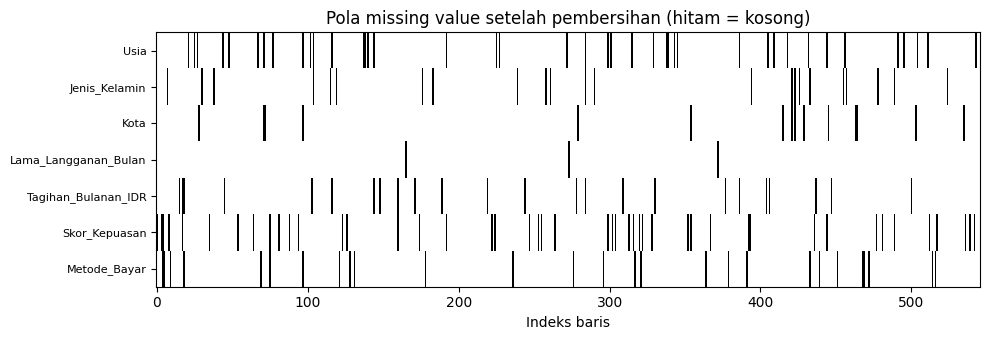

In [156]:
# Pola missing value setelah pembersihan dan nilai mustahil dijadikan NaN
kolom_m = [c for c in data.columns if data[c].isnull().any()]
plt.figure(figsize=(10, 3.5))
plt.imshow(data[kolom_m].isnull().values.T, aspect="auto", interpolation="nearest", cmap="gray_r")
plt.yticks(range(len(kolom_m)), kolom_m, fontsize=8)
plt.xlabel("Indeks baris"); plt.title("Pola missing value setelah pembersihan (hitam = kosong)")
plt.tight_layout(); plt.show()

In [157]:
# Apakah missing berkaitan dengan kelompok tertentu? Proporsi missing Usia dan Skor menurut Churn
for c in ["Usia", "Skor_Kepuasan"]:
    print(c, "-> proporsi missing per kelompok Churn:")
    print(data.groupby("Churn")[c].apply(lambda s: s.isnull().mean()).round(3).to_string())

Usia -> proporsi missing per kelompok Churn:
Churn
0    0.074
1    0.082
Skor_Kepuasan -> proporsi missing per kelompok Churn:
Churn
0    0.087
1    0.066


In [158]:
# Statistik deskriptif sebelum imputasi
num_miss = ["Usia", "Skor_Kepuasan"]
stat_sebelum = data[num_miss].agg(["count", "mean", "median", "std", "min", "max"]).round(2)
print(stat_sebelum)
print("\nModus kolom kategorik:")
for c in ["Jenis_Kelamin", "Kota", "Metode_Bayar"]:
    print(f"  {c:14s}: {data[c].mode()[0]}  (muncul {data[c].value_counts().iloc[0]} dari {data[c].notnull().sum()} nilai terisi)")

          Usia  Skor_Kepuasan
count   505.00         500.00
mean     34.43           6.98
median   35.00           7.00
std       9.37           1.57
min      18.00           1.00
max      61.00          10.00

Modus kolom kategorik:
  Jenis_Kelamin : Laki-laki  (muncul 263 dari 523 nilai terisi)
  Kota          : Jakarta  (muncul 136 dari 531 nilai terisi)
  Metode_Bayar  : E-Wallet  (muncul 170 dari 519 nilai terisi)


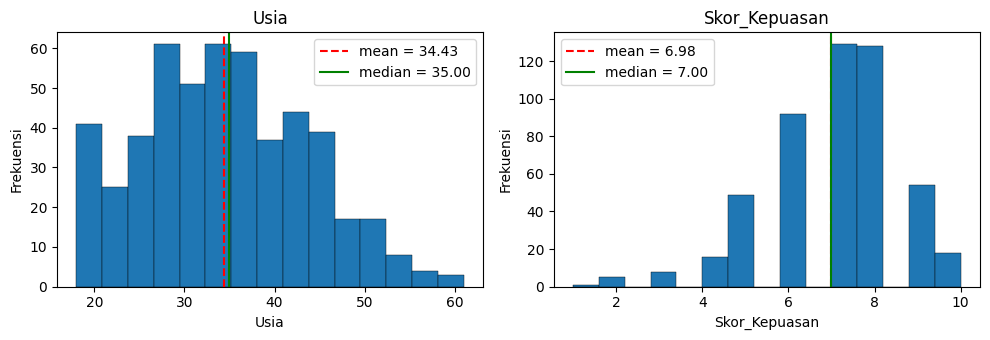

In [159]:
# Perbandingan mean dan median: selisih kecil artinya distribusi cukup simetris
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, c in zip(ax, num_miss):
    a.hist(data[c].dropna(), bins=15, edgecolor="black", linewidth=0.3)
    a.axvline(data[c].mean(), color="red", linestyle="--", label=f"mean = {data[c].mean():.2f}")
    a.axvline(data[c].median(), color="green", linestyle="-", label=f"median = {data[c].median():.2f}")
    a.set_title(c); a.set_xlabel(c); a.set_ylabel("Frekuensi"); a.legend()
plt.tight_layout(); plt.show()

**Perbandingan empat strategi penanganan missing value** (pada data saat ini, sebelum imputasi): hapus baris, hapus kolom, isi 0, dan isi dengan median.

In [160]:
def ringkas_strategi(nama, d):
    return [nama, d.shape[0], d.shape[1],
            d["Usia"].mean() if "Usia" in d else np.nan, d["Usia"].std() if "Usia" in d else np.nan,
            d["Skor_Kepuasan"].mean() if "Skor_Kepuasan" in d else np.nan,
            d["Skor_Kepuasan"].std() if "Skor_Kepuasan" in d else np.nan]

d_baris = data.dropna()
d_kolom = data.dropna(axis=1)
d_nol = data.copy();    d_nol[num_miss] = d_nol[num_miss].fillna(0)
d_med = data.copy();    d_med[num_miss] = d_med[num_miss].fillna(d_med[num_miss].median())

tabel_strategi = pd.DataFrame([
    ringkas_strategi("Data asli (belum ditangani)", data),
    ringkas_strategi("Hapus baris (dropna)", d_baris),
    ringkas_strategi("Hapus kolom (dropna axis=1)", d_kolom),
    ringkas_strategi("Isi 0", d_nol),
    ringkas_strategi("Isi median", d_med),
], columns=["Strategi", "Baris", "Kolom", "Mean_Usia", "Std_Usia", "Mean_Skor", "Std_Skor"]).round(2)
tabel_strategi

,Strategi,Baris,Kolom,Mean_Usia,Std_Usia,Mean_Skor,Std_Skor
0,Data asli (belum ditangani),546,17,34.43,9.37,6.98,1.57
1,Hapus baris (dropna),389,17,34.22,9.60,6.98,1.57
2,Hapus kolom (dropna axis=1),546,10,NaN,NaN,NaN,NaN
3,Isi 0,546,17,31.85,12.79,6.39,2.45
4,Isi median,546,17,34.48,9.01,6.98,1.50


In [161]:
# 1) Pemulihan berbasis aturan
n_tagihan = data["Tagihan_Bulanan_IDR"].isnull().sum()
data["Tagihan_Bulanan_IDR"] = data["Tagihan_Bulanan_IDR"].fillna((data["Tagihan_Bulanan_USD"] * KURS).round(-2))

n_lama = data["Lama_Langganan_Bulan"].isnull().sum()
lama_pulih = (data["Total_Tagihan_IDR"] / data["Tagihan_Bulanan_IDR"]).round()
data["Lama_Langganan_Bulan"] = data["Lama_Langganan_Bulan"].fillna(lama_pulih)
print(f"Tagihan_Bulanan_IDR dipulihkan: {n_tagihan} baris | Lama_Langganan_Bulan dipulihkan: {n_lama} baris")

# 2) Statistik deskriptif: median untuk numerik, modus untuk kategorik
for c in num_miss:
    data[c] = data[c].fillna(data[c].median())
for c in ["Jenis_Kelamin", "Kota", "Metode_Bayar"]:
    data[c] = data[c].fillna(data[c].mode()[0])

print("\nMissing value tersisa:", int(data.isnull().sum().sum()))

Tagihan_Bulanan_IDR dipulihkan: 24 baris | Lama_Langganan_Bulan dipulihkan: 3 baris

Missing value tersisa: 0


In [162]:
# Statistik sesudah imputasi dibandingkan dengan sebelumnya
stat_sesudah = data[num_miss].agg(["count", "mean", "median", "std", "min", "max"]).round(2)
print("Sebelum:\n", stat_sebelum, "\n\nSesudah:\n", stat_sesudah)

Sebelum:
           Usia  Skor_Kepuasan
count   505.00         500.00
mean     34.43           6.98
median   35.00           7.00
std       9.37           1.57
min      18.00           1.00
max      61.00          10.00 

Sesudah:
           Usia  Skor_Kepuasan
count   546.00         546.00
mean     34.48           6.98
median   35.00           7.00
std       9.01           1.50
min      18.00           1.00
max      61.00          10.00


### 3.2 Inkonsistensi antar variabel

**Input:** Total_Tagihan_IDR, Tagihan_Bulanan_IDR, Lama_Langganan_Bulan, Paket.
**Proses:**
1. Total_Tagihan seharusnya sama dengan Tagihan_Bulanan x Lama_Langganan. Hitung selisihnya, lalu hitung ulang Total untuk baris yang selisihnya lebih dari 1%.
2. Tiap Paket punya rentang harga yang jelas. Baris dengan Paket yang tidak cocok dengan harganya diperbaiki berdasarkan rentang harga. **Asumsi:** yang keliru adalah label Paket, bukan harganya, karena rentang harga ketiga paket terpisah jelas (ada celah antar paket) dan sebagian besar baris sudah cocok. Tidak ada sumber pembanding lain di data, sehingga asumsi ini dicatat di laporan.

**Output:** Total_Tagihan dan Paket konsisten dengan kolom lain.

In [163]:
total_hitung = data["Tagihan_Bulanan_IDR"] * data["Lama_Langganan_Bulan"]
rasio = (data["Total_Tagihan_IDR"] / total_hitung).round(2)
mask_total = (data["Total_Tagihan_IDR"] - total_hitung).abs() > 0.01 * total_hitung
print("Baris Total_Tagihan tidak konsisten:", mask_total.sum())
print(pd.DataFrame({"Total_di_data": data.loc[mask_total, "Total_Tagihan_IDR"],
                    "Tagihan x Lama": total_hitung[mask_total],
                    "Rasio": rasio[mask_total]}))

Baris Total_Tagihan tidak konsisten: 4
     Total_di_data  Tagihan x Lama  Rasio
60     644292000.0      21476400.0   30.0
137    181872000.0       6062400.0   30.0
243    159831000.0       5327700.0   30.0
497    763200000.0      25440000.0   30.0


In [164]:
data.loc[mask_total, "Total_Tagihan_IDR"] = total_hitung[mask_total]
print("Sisa baris tidak konsisten:", ((data["Total_Tagihan_IDR"] - data["Tagihan_Bulanan_IDR"] * data["Lama_Langganan_Bulan"]).abs()
                                   > 0.01 * data["Tagihan_Bulanan_IDR"] * data["Lama_Langganan_Bulan"]).sum())

Sisa baris tidak konsisten: 0


In [165]:
# Rentang harga per Paket (tagihan bulanan)
print(data.groupby("Paket")["Tagihan_Bulanan_IDR"].describe().round(0))

# Celah harga antar paket (dasar penentuan batas 330.000 dan 520.000)
bersih_dulu = data[data["Paket"].isin(["Basic", "Standard", "Premium"])]
print("Persentil 5 dan 95 tagihan per paket:")
print(bersih_dulu.groupby("Paket")["Tagihan_Bulanan_IDR"].quantile([0.05, 0.95]).unstack().round(0))

paket_harga = pd.cut(data["Tagihan_Bulanan_IDR"], bins=[0, 330000, 520000, np.inf],
                     labels=["Basic", "Standard", "Premium"])
print("\nPaket di data (baris) vs Paket menurut rentang harga (kolom):")
print(pd.crosstab(data["Paket"], paket_harga))
print("Baris Paket tidak cocok dengan harga:", (data["Paket"] != paket_harga.astype(str)).sum())

          count      mean       std       min       25%       50%       75%       max
Paket                                                                                
Basic     217.0  260045.0   51593.0  227500.0  243600.0  248900.0  255400.0  654400.0
Premium   146.0  599615.0  115977.0  240400.0  625900.0  643700.0  655750.0  715000.0
Standard  183.0  399415.0   11780.0  363300.0  391500.0  399600.0  407350.0  431200.0
Persentil 5 dan 95 tagihan per paket:
              0.05      0.95
Paket                       
Basic     236840.0  395560.0
Premium   292500.0  679725.0
Standard  378970.0  419370.0

Paket di data (baris) vs Paket menurut rentang harga (kolom):
Tagihan_Bulanan_IDR  Basic  Standard  Premium
Paket                                        
Basic                  204        11        2
Premium                  8        16      122
Standard                 0       183        0
Baris Paket tidak cocok dengan harga: 37


In [166]:
data["Paket"] = paket_harga.astype(str)
print(data.groupby("Paket")["Tagihan_Bulanan_IDR"].agg(["count", "min", "max"]))

          count       min       max
Paket                              
Basic       212  227500.0  266800.0
Premium     124  595700.0  715000.0
Standard    210  363300.0  436800.0


### 3.3 Outlier

**Input:** kolom numerik hasil tahap sebelumnya.
**Proses:** deteksi dengan histogram dan boxplot, lalu hitung batas IQR (Q1 - 1.5 x IQR dan Q3 + 1.5 x IQR) dan, sebagai pembanding, Z-score (|z| > 3). Outlier yang berupa anomali (Jumlah_Keluhan = 40) diperlakukan dengan capping. Nilai yang masih wajar tidak dipotong: Usia 59 sampai 61 tahun, lama langganan sampai 72 bulan, harga paket Premium, total tagihan, dan pemakaian data paket Premium. Variabel yang masih miring ditangani dengan transformasi log di Tahap 5.3.
**Output:** nilai ekstrem dibatasi pada batas IQR, jumlah baris tetap.

In [167]:
num_cols = ["Usia", "Lama_Langganan_Bulan", "Tagihan_Bulanan_IDR", "Total_Tagihan_IDR",
            "Jumlah_Keluhan", "Skor_Kepuasan", "Penggunaan_Data_GB"]

def batas_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

baris = []
for c in num_cols:
    lo, hi = batas_iqr(data[c])
    n_out = int(((data[c] < lo) | (data[c] > hi)).sum())
    z = (data[c] - data[c].mean()) / data[c].std()
    baris.append([c, round(lo, 1), round(hi, 1), data[c].min(), data[c].max(), n_out, int((z.abs() > 3).sum())])
tabel_outlier = pd.DataFrame(baris, columns=["Kolom", "Batas_bawah", "Batas_atas", "Min", "Maks", "Outlier_IQR", "Outlier_Zscore"])
tabel_outlier

,Kolom,Batas_bawah,Batas_atas,Min,Maks,Outlier_IQR,Outlier_Zscore
0,Usia,10.0,58.0,18.0,61.0,3,0
1,Lama_Langganan_Bulan,-18.0,62.0,1.0,72.0,10,6
2,Tagihan_Bulanan_IDR,412.5,670312.5,227500.0,715000.0,16,0
3,Total_Tagihan_IDR,-9326250.0,26284550.0,244100.0,46720800.0,25,11
4,Jumlah_Keluhan,-3.0,5.0,0.0,40.0,4,4
5,Skor_Kepuasan,3.0,11.0,1.0,10.0,6,6
6,Penggunaan_Data_GB,-321.4,1187.9,153.9,1198.3,2,0


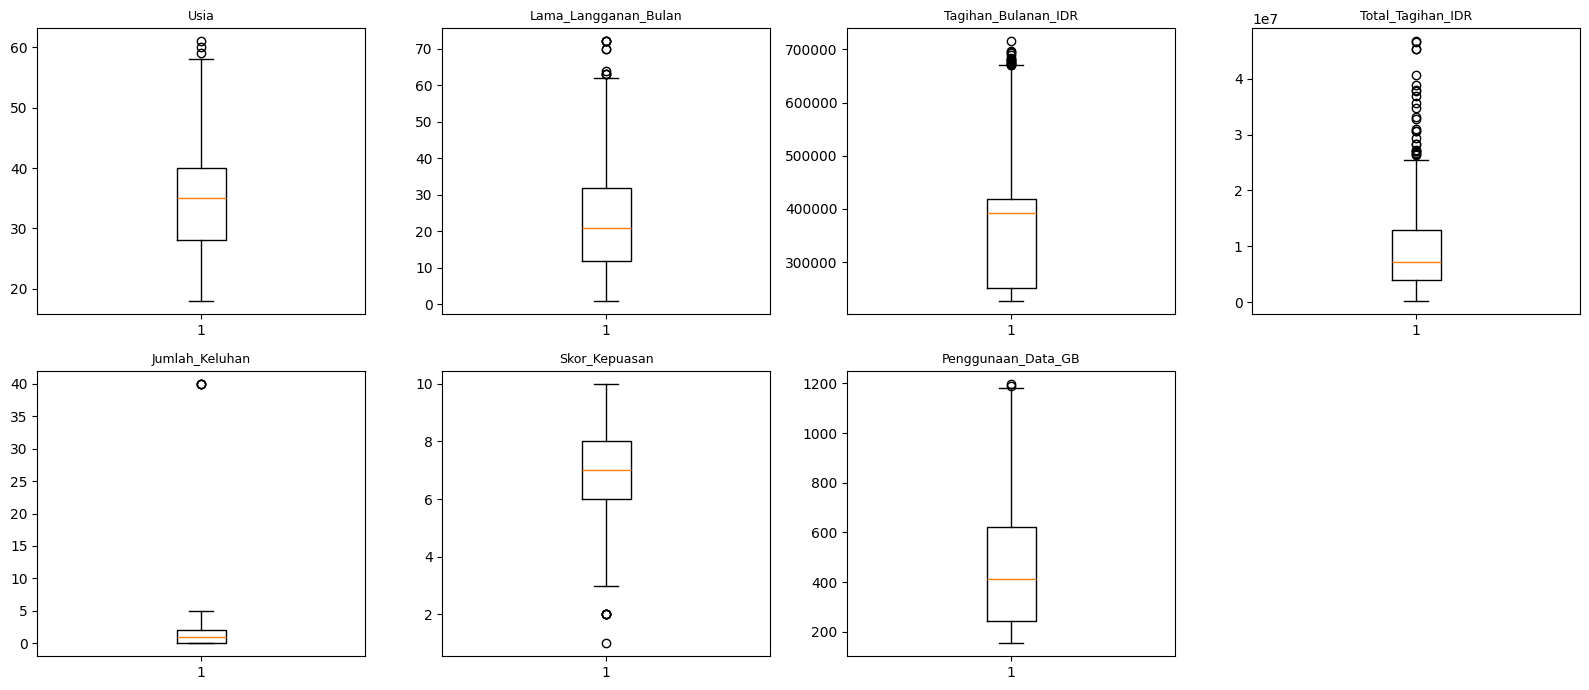

In [168]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    ax.boxplot(data[c], vert=True)
    ax.set_title(c, fontsize=9)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

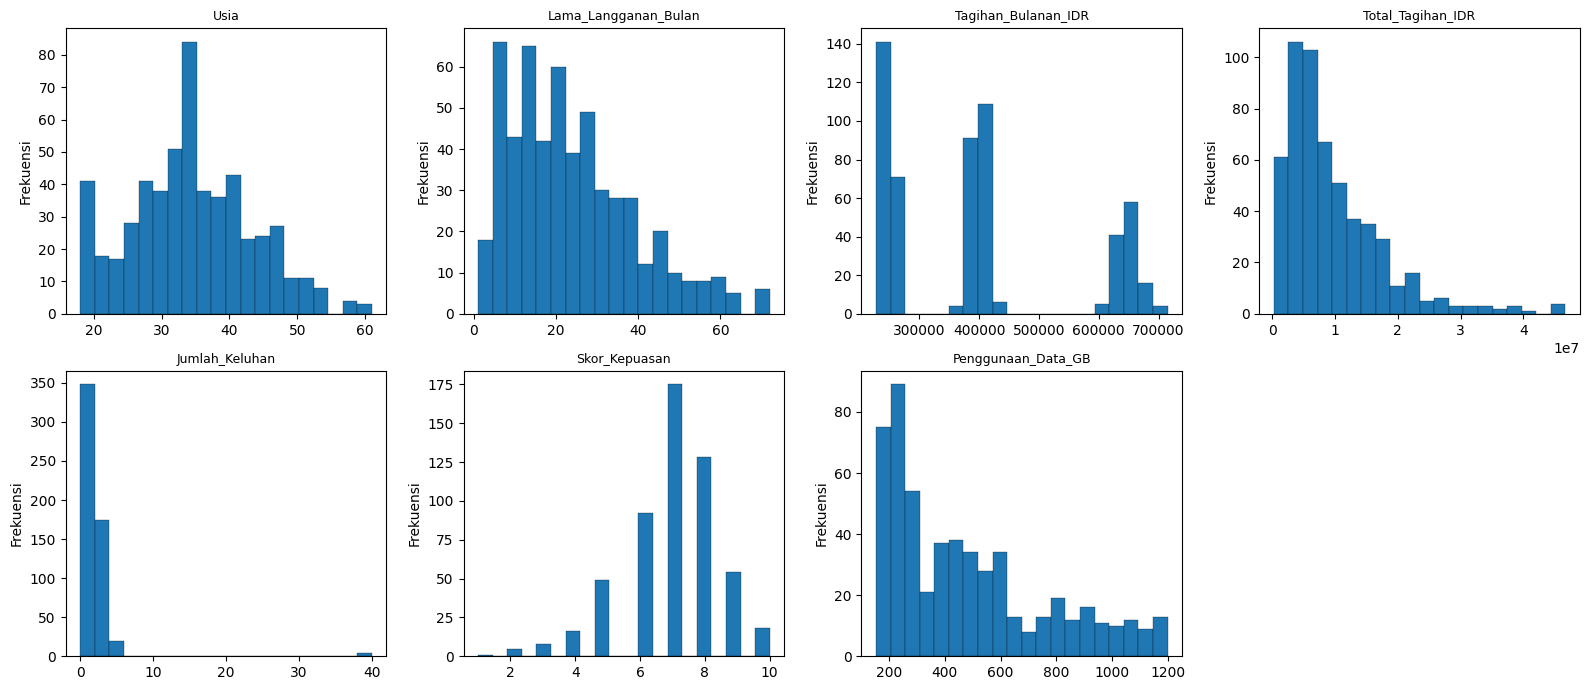

In [169]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(data[c], bins=20, edgecolor="black", linewidth=0.2)
    ax.set_title(c, fontsize=9); ax.set_ylabel("Frekuensi")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [170]:
# Capping hanya untuk kolom yang outlier-nya merupakan anomali
kolom_cap = ["Jumlah_Keluhan"]
for c in kolom_cap:
    lo, hi = batas_iqr(data[c])
    lo = max(lo, 0)          # jumlah keluhan tidak mungkin negatif
    n = int(((data[c] < lo) | (data[c] > hi)).sum())
    data[c] = data[c].clip(lower=lo, upper=hi)
    print(f"{c}: {n} nilai dibatasi ke rentang [{lo:.1f}, {hi:.1f}] | maks sekarang = {data[c].max():.1f}")

Jumlah_Keluhan: 4 nilai dibatasi ke rentang [0.0, 5.0] | maks sekarang = 5.0


### 3.4 Pemeriksaan akhir

**Input:** `data` setelah seluruh Tahap 2 dan tahap 3.1 sampai 3.3.
**Proses:** cek tipe data, missing value, duplikat, rentang nilai, dan kategori.
**Output:** `data` bersih yang disimpan sebagai `data_bersih`.

In [171]:
print("Ukuran:", data.shape, "| missing:", int(data.isnull().sum().sum()), "| duplikat:", int(data.duplicated().sum()))
print(data.dtypes.to_string())
data.describe().T.round(2)

Ukuran: (546, 17) | missing: 0 | duplikat: 0
ID_Pelanggan                    object
Usia                           float64
Jenis_Kelamin                   object
Kota                            object
Paket                           object
Lama_Langganan_Bulan           float64
Tagihan_Bulanan_IDR            float64
Total_Tagihan_IDR              float64
Jumlah_Keluhan                   int64
Skor_Kepuasan                  float64
Metode_Bayar                    object
Tanggal_Daftar          datetime64[ns]
Tagihan_Bulanan_USD            float64
Negara                          object
Penggunaan_Data_GB             float64
Periode_Penggunaan              object
Churn                            int64


,count,mean,min,25%,50%,75%,max,std
Usia,546.0,34.47619,18.0,28.0,35.0,40.0,61.0,9.010105
Lama_Langganan_Bulan,546.0,23.840659,1.0,12.0,21.0,32.0,72.0,15.097794
Tagihan_Bulanan_IDR,546.0,397557.692308,227500.0,251625.0,393100.0,419100.0,715000.0,152142.973275
Total_Tagihan_IDR,546.0,9658684.981685,244100.0,4027800.0,7266000.0,12930500.0,46720800.0,7872567.844757
Jumlah_Keluhan,546.0,1.269231,0.0,0.0,1.0,2.0,5.0,1.156888
Skor_Kepuasan,546.0,6.979853,1.0,6.0,7.0,8.0,10.0,1.500323
Tanggal_Daftar,546,2023-12-16 18:43:30.989010944,2020-01-02 00:00:00,2023-04-16 00:00:00,2024-03-11 00:00:00,2024-12-06 00:00:00,2025-11-01 00:00:00,NaN
Tagihan_Bulanan_USD,546.0,24.847619,14.22,15.7225,24.57,26.19,44.69,9.509057
Penggunaan_Data_GB,546.0,480.503114,153.9,244.55,412.1,621.875,1198.3,282.810895
Churn,546.0,0.111722,0.0,0.0,0.0,0.0,1.0,0.315313


In [172]:
for kolom in ["Jenis_Kelamin", "Kota", "Paket", "Metode_Bayar"]:
    print(kolom, "->", data[kolom].value_counts().to_dict())
data_bersih_penuh = data.copy()

Jenis_Kelamin -> {'Laki-laki': 286, 'Perempuan': 260}
Kota -> {'Jakarta': 151, 'Surabaya': 95, 'Bandung': 84, 'Medan': 58, 'Semarang': 56, 'Yogyakarta': 55, 'Makassar': 47}
Paket -> {'Basic': 212, 'Standard': 210, 'Premium': 124}
Metode_Bayar -> {'E-Wallet': 197, 'Transfer Bank': 166, 'Virtual Account': 106, 'Kartu Kredit': 77}


## Tahap 4: Reduksi Data

### 4.1 Seleksi Fitur (Feature Selection)

**Input:** `data` hasil cleansing (17 kolom).
**Proses:** periksa jumlah nilai unik tiap kolom, korelasi antar kolom numerik, dan relevansi kolom. Buang kolom yang konstan, redundan (termasuk yang dapat dihitung persis dari kolom lain), atau tidak relevan (feature selection).
**Output:** `data` dengan kolom yang relevan saja.

In [173]:
print("Jumlah nilai unik per kolom:")
print(data.nunique().to_string())

Jumlah nilai unik per kolom:
ID_Pelanggan            546
Usia                     41
Jenis_Kelamin             2
Kota                      7
Paket                     3
Lama_Langganan_Bulan     64
Tagihan_Bulanan_IDR     435
Total_Tagihan_IDR       542
Jumlah_Keluhan            6
Skor_Kepuasan            10
Metode_Bayar              4
Tanggal_Daftar           64
Tagihan_Bulanan_USD     373
Negara                    1
Penggunaan_Data_GB      516
Periode_Penggunaan        1
Churn                     2


                      Usia  Lama_Langganan_Bulan  Tagihan_Bulanan_IDR  Tagihan_Bulanan_USD  Total_Tagihan_IDR  Jumlah_Keluhan  Skor_Kepuasan  Penggunaan_Data_GB
Usia                  1.00                  0.01                 0.05                 0.05               0.06           -0.07           0.10                0.03
Lama_Langganan_Bulan  0.01                  1.00                 0.08                 0.08               0.83            0.03          -0.10                0.05
Tagihan_Bulanan_IDR   0.05                  0.08                 1.00                 1.00               0.54            0.06           0.01                0.83
Tagihan_Bulanan_USD   0.05                  0.08                 1.00                 1.00               0.54            0.06           0.01                0.83
Total_Tagihan_IDR     0.06                  0.83                 0.54                 0.54               1.00            0.06          -0.06                0.44
Jumlah_Keluhan       -0.07        

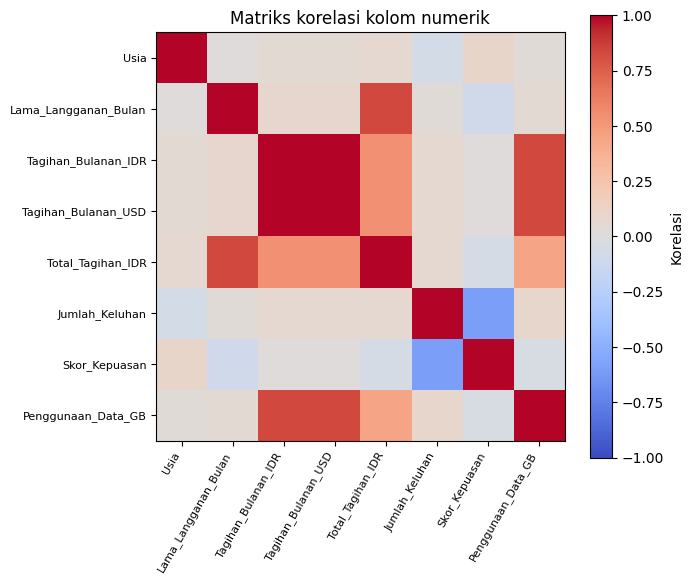

In [174]:
korelasi = data[["Usia", "Lama_Langganan_Bulan", "Tagihan_Bulanan_IDR", "Tagihan_Bulanan_USD",
                 "Total_Tagihan_IDR", "Jumlah_Keluhan", "Skor_Kepuasan", "Penggunaan_Data_GB"]].corr().round(2)
print(korelasi)

plt.figure(figsize=(7, 6))
plt.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(korelasi)), korelasi.columns, rotation=60, ha="right", fontsize=8)
plt.yticks(range(len(korelasi)), korelasi.columns, fontsize=8)
plt.colorbar(label="Korelasi")
plt.title("Matriks korelasi kolom numerik")
plt.tight_layout(); plt.show()

In [175]:
# Bukti redundansi: Total_Tagihan = Tagihan_Bulanan x Lama_Langganan (selisih <= 1% setelah tahap 3.2)
selisih = (data["Total_Tagihan_IDR"] - data["Tagihan_Bulanan_IDR"] * data["Lama_Langganan_Bulan"]).abs() / data["Total_Tagihan_IDR"]
print("Selisih relatif maks Total vs Tagihan x Lama:", round(selisih.max(), 4))

alasan = {
    "Negara": "konstan (hanya 1 nilai: Indonesia)",
    "Periode_Penggunaan": "konstan setelah disamakan ke bulanan",
    "Tagihan_Bulanan_USD": "redundan, korelasi 1.0 dengan Tagihan_Bulanan_IDR (kurs tetap)",
    "Total_Tagihan_IDR": "redundan, hasil kali Tagihan_Bulanan_IDR x Lama_Langganan_Bulan",
    "ID_Pelanggan": "identitas unik, tidak punya daya prediksi",
}
data = data.drop(columns=list(alasan))
for k, v in alasan.items():
    print(f"Dibuang: {k:22s} -> {v}")
print("\nUkuran data setelah reduksi:", data.shape)
print("Kolom tersisa:", list(data.columns))

data_bersih = data.copy()
data_bersih.to_csv("churn_isp_bersih.csv", index=False)

Selisih relatif maks Total vs Tagihan x Lama: 0.0004
Dibuang: Negara                 -> konstan (hanya 1 nilai: Indonesia)
Dibuang: Periode_Penggunaan     -> konstan setelah disamakan ke bulanan
Dibuang: Tagihan_Bulanan_USD    -> redundan, korelasi 1.0 dengan Tagihan_Bulanan_IDR (kurs tetap)
Dibuang: Total_Tagihan_IDR      -> redundan, hasil kali Tagihan_Bulanan_IDR x Lama_Langganan_Bulan
Dibuang: ID_Pelanggan           -> identitas unik, tidak punya daya prediksi

Ukuran data setelah reduksi: (546, 12)
Kolom tersisa: ['Usia', 'Jenis_Kelamin', 'Kota', 'Paket', 'Lama_Langganan_Bulan', 'Tagihan_Bulanan_IDR', 'Jumlah_Keluhan', 'Skor_Kepuasan', 'Metode_Bayar', 'Tanggal_Daftar', 'Penggunaan_Data_GB', 'Churn']


### 4.2 Reduksi Dimensi dengan PCA (Feature Extraction)

**Input:** kolom numerik kontinu hasil cleansing, distandardisasi dengan z-score.
**Proses:** hitung PCA penuh, lihat persentase varians yang dijelaskan tiap komponen, pilih jumlah komponen yang menjelaskan sekitar 80% varians, lalu lihat bobot variabel pada tiap komponen.
**Output:** jumlah komponen yang cukup dan tafsiran tiap komponen. Bagian ini adalah analisis tambahan. Matriks fitur untuk model tetap memakai fitur asli.

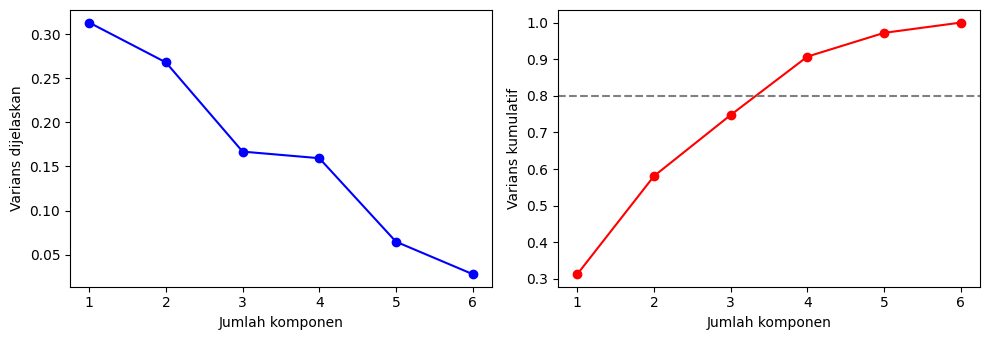

Komponen  Varians  Kumulatif
     PC1     31.3       31.3
     PC2     26.8       58.1
     PC3     16.7       74.8
     PC4     15.9       90.7
     PC5      6.5       97.2
     PC6      2.8      100.0


In [176]:
kolom_pca = ["Usia", "Lama_Langganan_Bulan", "Tagihan_Bulanan_IDR",
             "Jumlah_Keluhan", "Skor_Kepuasan", "Penggunaan_Data_GB"]
Xp = StandardScaler().fit_transform(data_bersih[kolom_pca])
Xp = pd.DataFrame(Xp, columns=kolom_pca)

model = PCA()
hasil = model.fit(Xp)
var = hasil.explained_variance_ratio_
kumulatif = np.cumsum(var)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(range(1, len(var) + 1), var, "-ob"); ax[0].set_xlabel("Jumlah komponen"); ax[0].set_ylabel("Varians dijelaskan")
ax[1].plot(range(1, len(var) + 1), kumulatif, "-or"); ax[1].axhline(0.8, linestyle="--", color="gray")
ax[1].set_xlabel("Jumlah komponen"); ax[1].set_ylabel("Varians kumulatif")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"Komponen": [f"PC{i+1}" for i in range(len(var))],
                    "Varians": (var * 100).round(1), "Kumulatif": (kumulatif * 100).round(1)}).to_string(index=False))

In [177]:
n_komponen = int(np.argmax(kumulatif >= 0.80) + 1)
print("Jumlah komponen untuk >= 80% varians:", n_komponen)

model_fix = PCA(n_components=n_komponen).fit(Xp)
pc = pd.DataFrame(model_fix.components_, columns=Xp.columns,
                  index=[f"PC{i+1}" for i in range(n_komponen)]).round(2)
pc

Jumlah komponen untuk >= 80% varians: 4


,Usia,Lama_Langganan_Bulan,Tagihan_Bulanan_IDR,Jumlah_Keluhan,Skor_Kepuasan,Penggunaan_Data_GB
PC1,0.02,0.13,0.65,0.26,-0.22,0.66
PC2,0.21,-0.09,0.26,-0.63,0.66,0.22
PC3,0.60,0.79,-0.07,-0.03,-0.05,-0.11
PC4,0.77,-0.59,-0.02,0.22,-0.10,-0.00


## Tahap 5: Transformasi Data

### 5.1 Agregasi per Periode dan Smoothing

**Input:** data bersih setelah Tahap 3 (satu baris per pelanggan, dengan Tanggal_Daftar).
**Proses:** kelompokkan pelanggan per tahun dan per bulan pendaftaran dengan `groupby`, hitung jumlah pelanggan, rata-rata skor kepuasan, rata-rata tagihan, dan tingkat churn. Lalu haluskan deret bulanan dengan moving average (window = 6 bulan) untuk meredam fluktuasi acak.
**Output:** tabel agregasi per tahun, tabel agregasi per bulan, dan grafik deret asli dibandingkan deret yang sudah dihaluskan. Tabel agregasi dipakai untuk analisis tren dan tidak masuk ke matriks fitur model.

In [178]:
bln = data_bersih_penuh.copy()
bln["Tahun"] = bln["Tanggal_Daftar"].dt.year
bln["Periode"] = bln["Tanggal_Daftar"].dt.to_period("M")

agg_tahun = bln.groupby("Tahun").agg(Jumlah_Pelanggan=("ID_Pelanggan", "count"),
                                      Rata_Skor=("Skor_Kepuasan", "mean"),
                                      Rata_Tagihan=("Tagihan_Bulanan_IDR", "mean"),
                                      Churn_Rate=("Churn", "mean")).round(3)
agg_tahun

,Jumlah_Pelanggan,Rata_Skor,Rata_Tagihan,Churn_Rate
Tahun,,,,
2020,17,6.412,449841.176,0.118
2021,29,6.552,407103.448,0.034
2022,66,6.697,407586.364,0.091
2023,125,7.192,410798.400,0.056
2024,182,6.923,382176.374,0.143
2025,127,7.173,392177.953,0.150


Jumlah periode bulanan: 64
Simpangan baku Rata_Skor asli      : 0.906
Simpangan baku setelah moving average: 0.433


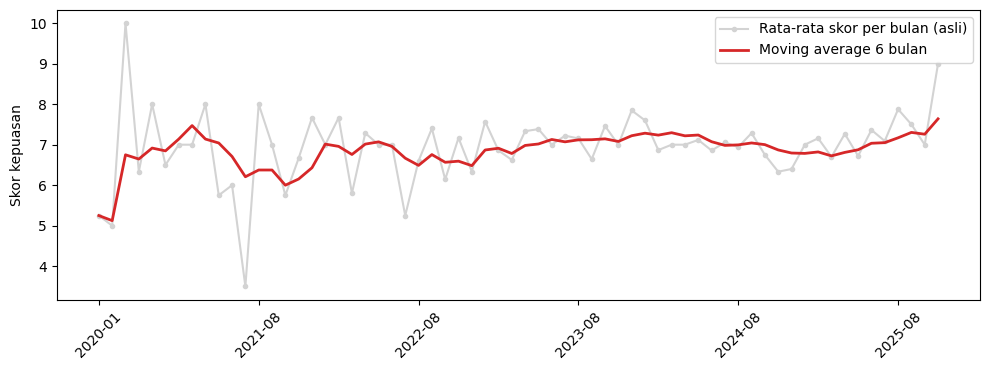

In [179]:
agg_bulan = bln.groupby("Periode").agg(Jumlah_Pelanggan=("ID_Pelanggan", "count"),
                                        Rata_Skor=("Skor_Kepuasan", "mean"),
                                        Churn_Rate=("Churn", "mean")).reset_index()
print("Jumlah periode bulanan:", len(agg_bulan))

agg_bulan["Skor_MA6"] = agg_bulan["Rata_Skor"].rolling(window=6, min_periods=1).mean()
print("Simpangan baku Rata_Skor asli      :", round(agg_bulan["Rata_Skor"].std(), 3))
print("Simpangan baku setelah moving average:", round(agg_bulan["Skor_MA6"].std(), 3))

plt.figure(figsize=(10, 3.8))
plt.plot(agg_bulan["Periode"].astype(str), agg_bulan["Rata_Skor"], color="lightgray", marker="o", markersize=3, label="Rata-rata skor per bulan (asli)")
plt.plot(agg_bulan["Periode"].astype(str), agg_bulan["Skor_MA6"], color="tab:red", linewidth=2, label="Moving average 6 bulan")
plt.xticks(range(0, len(agg_bulan), 12), agg_bulan["Periode"].astype(str)[::12], rotation=45)
plt.ylabel("Skor kepuasan"); plt.legend(); plt.tight_layout(); plt.show()

### 5.2 Pembuatan fitur baru (attribute construction)

**Input:** Tanggal_Daftar, Jumlah_Keluhan, Lama_Langganan_Bulan, Tagihan_Bulanan_IDR, Penggunaan_Data_GB.
**Proses:** bentuk tiga fitur turunan: Tahun_Daftar (dari tanggal), Keluhan_per_Bulan (keluhan dibagi lama langganan), dan Biaya_per_GB (tagihan dibagi pemakaian data). Kolom tanggal dibuang setelah informasinya diambil.
**Output:** tiga kolom baru yang lebih informatif daripada kolom asalnya.

In [180]:
data = data_bersih.copy()
data["Tahun_Daftar"] = data["Tanggal_Daftar"].dt.year
data["Keluhan_per_Bulan"] = (data["Jumlah_Keluhan"] / data["Lama_Langganan_Bulan"]).round(4)
data["Biaya_per_GB"] = (data["Tagihan_Bulanan_IDR"] / data["Penggunaan_Data_GB"]).round(1)
data = data.drop(columns="Tanggal_Daftar")
data[["Tahun_Daftar", "Keluhan_per_Bulan", "Biaya_per_GB"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Tahun_Daftar,546.0,2023.478,1.285,2020.0,2023.0,2024.00,2024.000,2025.0
Keluhan_per_Bulan,546.0,0.089,0.139,0.0,0.0,0.05,0.100,1.5
Biaya_per_GB,546.0,966.499,359.729,228.7,767.4,924.45,1092.375,4241.1


### 5.3 Transformasi log untuk data miring

**Input:** seluruh kolom numerik kontinu.
**Proses:** hitung skewness. Kolom dengan skewness di atas 1 (miring ke kanan) ditransformasi dengan `log1p`, yaitu log(1 + x), supaya aman untuk nilai 0.
**Output:** distribusi lebih simetris.

In [181]:
kontinu = ["Usia", "Lama_Langganan_Bulan", "Tagihan_Bulanan_IDR",
           "Penggunaan_Data_GB", "Keluhan_per_Bulan", "Biaya_per_GB"]
skew_awal = data[kontinu].skew().round(2)
print("Skewness sebelum transformasi:")
print(skew_awal.to_string())
kolom_log = list(skew_awal[skew_awal > 1].index)
print("\nKolom yang ditransformasi log1p:", kolom_log)

Skewness sebelum transformasi:
Usia                    0.19
Lama_Langganan_Bulan    0.89
Tagihan_Bulanan_IDR     0.68
Penggunaan_Data_GB      0.87
Keluhan_per_Bulan       4.13
Biaya_per_GB            3.18

Kolom yang ditransformasi log1p: ['Keluhan_per_Bulan', 'Biaya_per_GB']


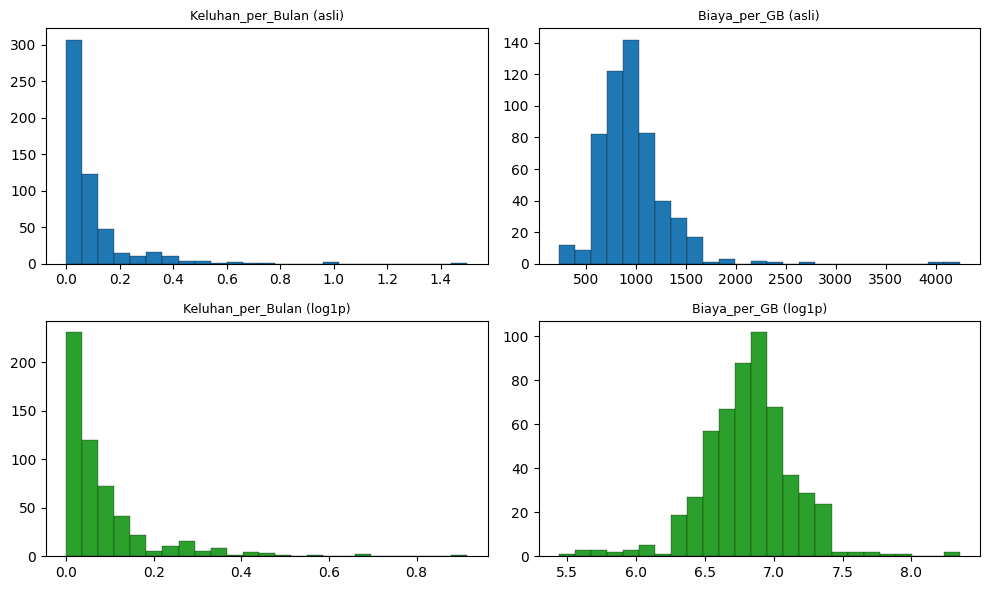

In [182]:
fig, axes = plt.subplots(2, len(kolom_log), figsize=(5 * len(kolom_log), 6))
axes = np.atleast_2d(axes)
for j, c in enumerate(kolom_log):
    axes[0, j].hist(data[c], bins=25, edgecolor="black", linewidth=0.2)
    axes[0, j].set_title(f"{c} (asli)", fontsize=9)
    axes[1, j].hist(np.log1p(data[c]), bins=25, edgecolor="black", linewidth=0.2, color="tab:green")
    axes[1, j].set_title(f"{c} (log1p)", fontsize=9)
plt.tight_layout(); plt.show()

In [183]:
for c in kolom_log:
    data[c] = np.log1p(data[c])
print("Skewness sesudah transformasi:")
print(data[kontinu].skew().round(2).to_string())

Skewness sesudah transformasi:
Usia                    0.19
Lama_Langganan_Bulan    0.89
Tagihan_Bulanan_IDR     0.68
Penggunaan_Data_GB      0.87
Keluhan_per_Bulan       2.86
Biaya_per_GB           -0.19


### 5.4 Diskretisasi (binning)

**Input:** Usia dan Lama_Langganan_Bulan.
**Proses:** `pd.cut` untuk equal-width binning (Usia) dan `pd.qcut` untuk equal-frequency binning (Lama_Langganan).
**Output:** dua kolom kategori baru. Kolom ini ditampilkan sebagai demonstrasi dan tidak dimasukkan ke matriks fitur akhir karena informasinya sudah ada di kolom numeriknya.

In [184]:
diskret = data_bersih[["Usia", "Lama_Langganan_Bulan"]].copy()
diskret["Usia_EW"] = pd.cut(diskret["Usia"], bins=4, labels=["Muda", "Dewasa Muda", "Dewasa", "Senior"])
diskret["Usia_EF"] = pd.qcut(diskret["Usia"], q=4, labels=["Q1 (termuda)", "Q2", "Q3", "Q4 (tertua)"])
diskret["Lama_Bin"] = pd.qcut(diskret["Lama_Langganan_Bulan"], q=3, labels=["Baru", "Menengah", "Lama"])

print("Batas equal-width Usia     :", pd.cut(diskret["Usia"], bins=4).cat.categories.astype(str).tolist())
print("Batas equal-frequency Usia :", pd.qcut(diskret["Usia"], q=4).cat.categories.astype(str).tolist())
print("\nEqual-width (Usia)         :", diskret["Usia_EW"].value_counts().sort_index().to_dict())
print("Equal-frequency (Usia)     :", diskret["Usia_EF"].value_counts().sort_index().to_dict())
print("Equal-frequency (Lama)     :", diskret["Lama_Bin"].value_counts().sort_index().to_dict())
diskret.head()

Batas equal-width Usia     : ['(17.957, 28.75]', '(28.75, 39.5]', '(39.5, 50.25]', '(50.25, 61.0]']
Batas equal-frequency Usia : ['(17.999, 28.0]', '(28.0, 35.0]', '(35.0, 40.0]', '(40.0, 61.0]']

Equal-width (Usia)         : {'Muda': 145, 'Dewasa Muda': 247, 'Dewasa': 128, 'Senior': 26}
Equal-frequency (Usia)     : {'Q1 (termuda)': 145, 'Q2': 173, 'Q3': 96, 'Q4 (tertua)': 132}
Equal-frequency (Lama)     : {'Baru': 192, 'Menengah': 181, 'Lama': 173}


,Usia,Lama_Langganan_Bulan,Usia_EW,Usia_EF,Lama_Bin
0,38.0,17.0,Dewasa Muda,Q3,Menengah
1,45.0,22.0,Dewasa,Q4 (tertua),Menengah
2,48.0,56.0,Dewasa,Q4 (tertua),Lama
3,36.0,8.0,Dewasa Muda,Q3,Baru
4,36.0,11.0,Dewasa Muda,Q3,Baru


### 5.5 Normalisasi dan standardisasi (demonstrasi pada kolom Usia)

**Input:** kolom Usia (sebelum log, setelah cleansing).
**Proses:** terapkan empat metode seperti di materi, masing-masing dengan rumus manual dan dengan library, lalu bandingkan hasilnya.
**Output:** tabel perbandingan hasil normalisasi. Metode yang dipakai pada data final dijelaskan di Tahap 6.

In [185]:
u = data_bersih[["Usia"]].copy()
v = u["Usia"]

# a. Decimal scaling
k = len(str(int(v.abs().max())))
u["decimal"] = v / 10**k

# b. Min-Max (manual dan library)
u["minmax_manual"] = (v - v.min()) / (v.max() - v.min())
u["minmax_lib"] = MinMaxScaler().fit_transform(u[["Usia"]])

# c. Z-score (manual dan library)
u["z_manual"] = (v - v.mean()) / v.std()
u["z_lib"] = StandardScaler().fit_transform(u[["Usia"]])

# d. Robust scaling (manual dan library)
iqr = v.quantile(0.75) - v.quantile(0.25)
u["robust_manual"] = (v - v.median()) / iqr
u["robust_lib"] = RobustScaler().fit_transform(u[["Usia"]])

print("k decimal scaling =", k)
u.head(8).round(4)

k decimal scaling = 2


,Usia,decimal,minmax_manual,minmax_lib,z_manual,z_lib,robust_manual,robust_lib
0,38.0,0.38,0.4651,0.4651,0.3911,0.3915,0.2500,0.2500
1,45.0,0.45,0.6279,0.6279,1.1680,1.1691,0.8333,0.8333
2,48.0,0.48,0.6977,0.6977,1.5010,1.5023,1.0833,1.0833
3,36.0,0.36,0.4186,0.4186,0.1691,0.1693,0.0833,0.0833
4,36.0,0.36,0.4186,0.4186,0.1691,0.1693,0.0833,0.0833
5,21.0,0.21,0.0698,0.0698,-1.4957,-1.4970,-1.1667,-1.1667
6,39.0,0.39,0.4884,0.4884,0.5021,0.5025,0.3333,0.3333
7,21.0,0.21,0.0698,0.0698,-1.4957,-1.4970,-1.1667,-1.1667


In [186]:
print("Min-Max manual = library :", np.allclose(u["minmax_manual"], u["minmax_lib"]))
print("Robust manual  = library :", np.allclose(u["robust_manual"], u["robust_lib"]))
print("Z-score manual = library :", np.allclose(u["z_manual"], u["z_lib"]),
      "(beda kecil: pandas .std() memakai n-1, StandardScaler memakai n)")
print("Z-score setelah koreksi ddof=0:", np.allclose((v - v.mean()) / v.std(ddof=0), u["z_lib"]))

Min-Max manual = library : True
Robust manual  = library : True
Z-score manual = library : False (beda kecil: pandas .std() memakai n-1, StandardScaler memakai n)
Z-score setelah koreksi ddof=0: True


**Perbandingan tiga metode pada kolom dengan nilai ekstrem** (Total_Tagihan_IDR dari data bersih sebelum reduksi kolom): min-max, z-score, dan robust scaling. Kolom ini dipilih karena ekornya panjang, sehingga pengaruh outlier pada tiap metode terlihat jelas.

In [187]:
t = data_bersih_penuh[["Total_Tagihan_IDR"]]
hasil_skala = pd.DataFrame({
    "Min-Max": MinMaxScaler().fit_transform(t)[:, 0],
    "Z-score": StandardScaler().fit_transform(t)[:, 0],
    "Robust": RobustScaler().fit_transform(t)[:, 0],
})
tabel_skala = hasil_skala.agg(["min", "max", "mean", "std"]).T
tabel_skala["Persen_data_dalam_[-1,1]"] = ((hasil_skala.abs() <= 1).mean() * 100).round(1)
tabel_skala["Jumlah_|x|>3"] = (hasil_skala.abs() > 3).sum()
tabel_skala.round(3)

,min,max,mean,std,"Persen_data_dalam_[-1,1]",Jumlah_|x|>3
Min-Max,0.000,1.000,0.203,0.169,100.0,0
Z-score,-1.197,4.712,0.000,1.001,80.6,11
Robust,-0.789,4.432,0.269,0.884,83.5,11


### 5.6 Encoding data kategorik

**Input:** Paket (ordinal), Jenis_Kelamin, Kota, Metode_Bayar (nominal).
**Proses:**
- Paket: `LabelEncoder` ditampilkan dulu, lalu dibandingkan dengan `OrdinalEncoder` yang urutannya ditentukan manual.
- Jenis_Kelamin, Kota, Metode_Bayar: one-hot encoding dengan `pd.get_dummies`.

**Output:** semua fitur berupa angka.

In [188]:
le = LabelEncoder()
perbandingan = pd.DataFrame({"Paket": data["Paket"], "LabelEncoder": le.fit_transform(data["Paket"])})
print("LabelEncoder mengurutkan abjad:", dict(zip(le.classes_, range(len(le.classes_)))))
print("Urutan ini keliru untuk data ordinal (Premium bernilai lebih kecil dari Standard).\n")

oe = OrdinalEncoder(categories=[["Basic", "Standard", "Premium"]])
perbandingan["OrdinalEncoder"] = oe.fit_transform(data[["Paket"]]).astype(int)
perbandingan.drop_duplicates().sort_values("OrdinalEncoder")

LabelEncoder mengurutkan abjad: {'Basic': 0, 'Premium': 1, 'Standard': 2}
Urutan ini keliru untuk data ordinal (Premium bernilai lebih kecil dari Standard).



,Paket,LabelEncoder,OrdinalEncoder
5,Basic,0,0
0,Standard,2,1
12,Premium,1,2


In [189]:
data["Paket_Enc"] = oe.fit_transform(data[["Paket"]]).astype(int)
data = data.drop(columns="Paket")

data = pd.get_dummies(data, columns=["Jenis_Kelamin", "Kota", "Metode_Bayar"], dtype=int)
print("Ukuran data setelah encoding:", data.shape)
print(list(data.columns))
data.head()

Ukuran data setelah encoding: (546, 24)
['Usia', 'Lama_Langganan_Bulan', 'Tagihan_Bulanan_IDR', 'Jumlah_Keluhan', 'Skor_Kepuasan', 'Penggunaan_Data_GB', 'Churn', 'Tahun_Daftar', 'Keluhan_per_Bulan', 'Biaya_per_GB', 'Paket_Enc', 'Jenis_Kelamin_Laki-laki', 'Jenis_Kelamin_Perempuan', 'Kota_Bandung', 'Kota_Jakarta', 'Kota_Makassar', 'Kota_Medan', 'Kota_Semarang', 'Kota_Surabaya', 'Kota_Yogyakarta', 'Metode_Bayar_E-Wallet', 'Metode_Bayar_Kartu Kredit', 'Metode_Bayar_Transfer Bank', 'Metode_Bayar_Virtual Account']


,Usia,Lama_Langganan_Bulan,Tagihan_Bulanan_IDR,Jumlah_Keluhan,Skor_Kepuasan,Penggunaan_Data_GB,Churn,Tahun_Daftar,Keluhan_per_Bulan,Biaya_per_GB,Paket_Enc,Jenis_Kelamin_Laki-laki,Jenis_Kelamin_Perempuan,Kota_Bandung,Kota_Jakarta,Kota_Makassar,Kota_Medan,Kota_Semarang,Kota_Surabaya,Kota_Yogyakarta,Metode_Bayar_E-Wallet,Metode_Bayar_Kartu Kredit,Metode_Bayar_Transfer Bank,Metode_Bayar_Virtual Account
0,38.0,17.0,378900.0,0,7.0,155.7,0,2024,0.000000,7.797497,1,0,1,0,0,0,0,0,0,1,0,0,1,0
1,45.0,22.0,403900.0,1,6.0,403.7,1,2024,0.044495,6.909254,1,0,1,0,0,0,1,0,0,0,0,0,1,0
2,48.0,56.0,384400.0,1,9.0,430.9,0,2021,0.017742,6.794699,1,0,1,0,1,0,0,0,0,0,1,0,0,0
3,36.0,8.0,381300.0,0,7.0,334.7,1,2025,0.000000,7.038959,1,1,0,0,0,0,0,0,1,0,0,0,0,1
4,36.0,11.0,409700.0,1,7.0,357.0,0,2025,0.087003,7.046299,1,1,0,0,0,0,0,1,0,0,1,0,0,0


## Tahap 6: Ketidakseimbangan Kelas, Split, dan Standardisasi

**Input:** `data` hasil transformasi (semua fitur numerik, target Churn).
**Proses:**
1. Cek proporsi kelas Churn.
2. Bagi data latih dan uji 80:20 dengan `stratify` agar proporsi kelas terjaga.
3. Standardisasi (z-score) kolom kontinu. Scaler dilatih hanya pada data latih, lalu dipakai untuk data uji.
4. Terapkan **SMOTE-NC** hanya pada data latih. SMOTE biasa menginterpolasi semua kolom, sehingga kolom one-hot bisa bernilai pecahan (misalnya 0,37). SMOTE-NC menginterpolasi kolom numerik dan memilih kategori mayoritas tetangga untuk kolom kategorik. Data uji dibiarkan apa adanya supaya evaluasi tetap jujur.

**Output:** `X_train_sm`, `y_train_sm` (seimbang), serta `X_test`, `y_test` (distribusi asli).

{0: 485, 1: 61} | proporsi: {0: 0.888, 1: 0.112}


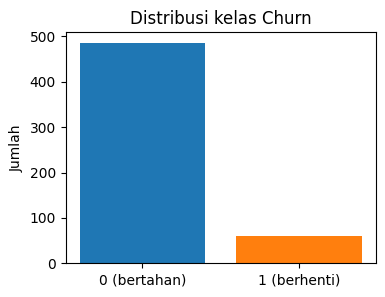

In [190]:
hitung = data["Churn"].value_counts().sort_index()
print(hitung.to_dict(), "| proporsi:", (hitung / hitung.sum()).round(3).to_dict())
plt.figure(figsize=(4, 3)); plt.bar(["0 (bertahan)", "1 (berhenti)"], hitung.values, color=["tab:blue", "tab:orange"])
plt.title("Distribusi kelas Churn"); plt.ylabel("Jumlah"); plt.show()

In [191]:
X = data.drop(columns="Churn")
y = data["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi churn latih:", round(y_train.mean(), 3), "| uji:", round(y_test.mean(), 3))

Data latih: (436, 23) | Data uji: (110, 23)
Proporsi churn latih: 0.112 | uji: 0.109


In [192]:
kolom_skala = [c for c in kontinu if c in X.columns] + ["Jumlah_Keluhan", "Skor_Kepuasan", "Tahun_Daftar"]
scaler = StandardScaler().fit(X_train[kolom_skala])
X_train = X_train.copy(); X_test = X_test.copy()
X_train[kolom_skala] = scaler.transform(X_train[kolom_skala])
X_test[kolom_skala] = scaler.transform(X_test[kolom_skala])

print("Kolom yang distandardisasi:", kolom_skala)
print("Rata-rata data latih (harus mendekati 0):", X_train[kolom_skala].mean().abs().max())

Kolom yang distandardisasi: ['Usia', 'Lama_Langganan_Bulan', 'Tagihan_Bulanan_IDR', 'Penggunaan_Data_GB', 'Keluhan_per_Bulan', 'Biaya_per_GB', 'Jumlah_Keluhan', 'Skor_Kepuasan', 'Tahun_Daftar']
Rata-rata data latih (harus mendekati 0): 3.048326117521256e-14


Metode oversampling: imbalanced-learn SMOTENC
Data latih sebelum SMOTE-NC: {0: 387, 1: 49}
Data latih sesudah SMOTE-NC: {0: 387, 1: 387}
Data uji (tidak diubah)    : {0: 98, 1: 12}
Semua kolom kategorik tetap bulat: True


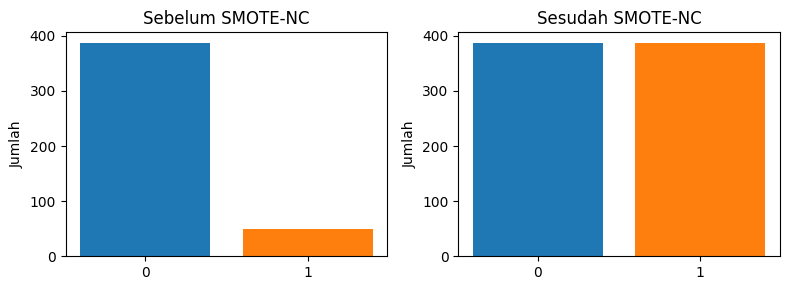

In [193]:
# Kolom kategorik (hasil one-hot dan Paket ordinal) ditandai agar tidak diinterpolasi
kolom_kat = [c.startswith(("Jenis_Kelamin_", "Kota_", "Metode_Bayar_")) or c == "Paket_Enc" for c in X_train.columns]

def smote_nc_manual(X, y, kat, k=5, seed=42):
    """Implementasi SMOTE-NC sederhana, dipakai bila library imbalanced-learn belum terpasang."""
    rng = np.random.RandomState(seed)
    kat = np.array(kat)
    A = X.to_numpy(float); yy = y.to_numpy()
    minor = A[yy == 1]
    n_baru = int((yy == 0).sum() - (yy == 1).sum())
    num, cat = minor[:, ~kat], minor[:, kat]
    penalti = np.median(num.std(axis=0))
    d2 = ((num[:, None, :] - num[None, :, :]) ** 2).sum(-1) + penalti ** 2 * (cat[:, None, :] != cat[None, :, :]).sum(-1)
    np.fill_diagonal(d2, np.inf)
    tetangga = np.argsort(d2, axis=1)[:, :k]
    baru = np.zeros((n_baru, A.shape[1]))
    for n in range(n_baru):
        i = rng.randint(len(minor)); j = rng.choice(tetangga[i])
        v = minor[i].copy()
        v[~kat] = num[i] + rng.rand() * (num[j] - num[i])
        for col in np.where(kat)[0]:
            nilai, jml = np.unique(minor[tetangga[i], col], return_counts=True)
            v[col] = nilai[np.argmax(jml)]
        baru[n] = v
    Xb = pd.DataFrame(np.vstack([A, baru]), columns=X.columns)
    yb = pd.Series(np.concatenate([yy, np.ones(n_baru, dtype=int)]), name=y.name)
    return Xb, yb

try:
    from imblearn.over_sampling import SMOTENC
    X_train_sm, y_train_sm = SMOTENC(categorical_features=kolom_kat, random_state=42).fit_resample(X_train, y_train)
    metode_smote = "imbalanced-learn SMOTENC"
except ImportError:      # pip install imbalanced-learn bila ingin memakai library
    X_train_sm, y_train_sm = smote_nc_manual(X_train, y_train, kolom_kat)
    metode_smote = "implementasi manual SMOTE-NC (imbalanced-learn tidak terpasang)"
print("Metode oversampling:", metode_smote)

sebelum = y_train.value_counts().sort_index()
sesudah = y_train_sm.value_counts().sort_index()
print("Data latih sebelum SMOTE-NC:", sebelum.to_dict())
print("Data latih sesudah SMOTE-NC:", sesudah.to_dict())
print("Data uji (tidak diubah)    :", y_test.value_counts().sort_index().to_dict())

# Pemeriksaan: kolom kategorik hasil sintetis harus tetap bulat (tidak ada nilai pecahan seperti 0,37)
kat_nama = [c for c, f in zip(X_train.columns, kolom_kat) if f]
print("Semua kolom kategorik tetap bulat:", bool(np.allclose(X_train_sm[kat_nama].to_numpy(), X_train_sm[kat_nama].to_numpy().round())))

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
for a, s, t in zip(ax, [sebelum, sesudah], ["Sebelum SMOTE-NC", "Sesudah SMOTE-NC"]):
    a.bar(["0", "1"], s.values, color=["tab:blue", "tab:orange"]); a.set_title(t); a.set_ylabel("Jumlah")
plt.tight_layout(); plt.show()


## Ringkasan Hasil

**Input:** dataset awal (565 x 17) dan seluruh tahap di atas.
**Proses:** bandingkan kondisi data sebelum dan sesudah preprocessing.
**Output:** tabel ringkasan untuk laporan.

In [194]:
ringkas = pd.DataFrame({
    "Tahap": ["Data mentah", "Setelah cleansing", "Setelah reduksi kolom", "Setelah transformasi (fitur akhir)",
              "Data latih setelah SMOTE-NC", "Data uji"],
    "Baris": [data_mentah.shape[0], data_bersih_penuh.shape[0], data_bersih.shape[0], X.shape[0],
              X_train_sm.shape[0], X_test.shape[0]],
    "Kolom": [data_mentah.shape[1], data_bersih_penuh.shape[1], data_bersih.shape[1], X.shape[1],
              X_train_sm.shape[1], X_test.shape[1]],
    "Missing": [int(data_mentah.isnull().sum().sum()), int(data_bersih_penuh.isnull().sum().sum()),
                int(data_bersih.isnull().sum().sum()), int(X.isnull().sum().sum()),
                int(X_train_sm.isnull().sum().sum()), int(X_test.isnull().sum().sum())],
})
ringkas

,Tahap,Baris,Kolom,Missing
0,Data mentah,565,17,157
1,Setelah cleansing,546,17,0
2,Setelah reduksi kolom,546,12,0
3,Setelah transformasi (fitur akhir),546,23,0
4,Data latih setelah SMOTE-NC,774,23,0
5,Data uji,110,23,0


In [195]:
print("Hasil cleansing disimpan di: churn_isp_bersih.csv")
print("Fitur akhir untuk model:", list(X.columns))

Hasil cleansing disimpan di: churn_isp_bersih.csv
Fitur akhir untuk model: ['Usia', 'Lama_Langganan_Bulan', 'Tagihan_Bulanan_IDR', 'Jumlah_Keluhan', 'Skor_Kepuasan', 'Penggunaan_Data_GB', 'Tahun_Daftar', 'Keluhan_per_Bulan', 'Biaya_per_GB', 'Paket_Enc', 'Jenis_Kelamin_Laki-laki', 'Jenis_Kelamin_Perempuan', 'Kota_Bandung', 'Kota_Jakarta', 'Kota_Makassar', 'Kota_Medan', 'Kota_Semarang', 'Kota_Surabaya', 'Kota_Yogyakarta', 'Metode_Bayar_E-Wallet', 'Metode_Bayar_Kartu Kredit', 'Metode_Bayar_Transfer Bank', 'Metode_Bayar_Virtual Account']


## Catatan dan Keterbatasan

- **Asumsi label Paket (tahap 3.2):** baris dengan harga di luar rentang paketnya dianggap salah label Paket, bukan salah harga. Tidak ada sumber pembanding lain di data.
- **Imputasi dan capping dihitung pada seluruh data sebelum split.** Ini kebocoran ringan (median dan batas IQR ikut memakai data uji). Untuk model produksi, hitung statistik ini hanya pada data latih, misalnya lewat `Pipeline` scikit-learn. Standardisasi dan SMOTE-NC di Tahap 6 sudah dilakukan hanya pada data latih.
- **Data sintetis:** pola churn tidak mewakili pelanggan ISP nyata, sehingga hasil preprocessing ini bersifat latihan.
- **Integrasi data (join dan append)** tidak diperlukan karena data hanya satu tabel.
